In [ ]:
from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV,
                                      cross_validate, StratifiedKFold)
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                             precision_recall_curve, average_precision_score, f1_score,
                             roc_auc_score, accuracy_score, precision_score, recall_score)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
import warnings
import numpy as np

warnings.filterwarnings('ignore')



## Loading Data

In [2]:
df = pd.read_csv('data/customer_churn.csv')

In [3]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370.0,71.0,5,17,3,1.0,1,30,197.640,0
1,0,0,39,0,318.0,5.0,7,4,2,1.0,2,25,46.035,0
2,10,0,37,0,2453.0,60.0,359,24,3,1.0,1,30,1536.520,0
3,10,0,38,0,4198.0,66.0,1,35,1,1.0,1,15,240.020,0
4,3,0,38,0,2393.0,58.0,2,33,1,1.0,1,15,145.805,0


## Description of Columns
Call Failures: number of call failures

Complains: binary (0: No complaint, 1: complaint)

Subscription Length: total months of subscription

Charge Amount: Ordinal attribute (0: lowest amount, 9: highest amount)

Seconds of Use: total seconds of calls

Frequency of use: total number of calls

Frequency of SMS: total number of text messages

Distinct Called Numbers: total number of distinct phone calls 

Age Group: ordinal attribute (1: younger age, 5: older age)

Tariff Plan: binary (1: Pay as you go, 2: contractual)

Status: binary (1: active, 2: non-active)

Churn: binary (1: churn, 0: non-churn) - Class label

Customer Value: The calculated value of customer

In [4]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3152.000000,3152.000000,3152.000000,3152.000000,3151.000000,3151.000000,3152.000000,3152.000000,3152.000000,3151.000000,3152.000000,3152.000000,3151.000000,3152.000000
mean,7.623414,0.076459,32.544734,0.942893,4471.040305,69.440495,73.132931,23.496827,2.827411,1.077753,1.248096,31.013642,470.832131,0.157043
std,7.263810,0.265774,8.571829,1.520798,4197.998455,57.415325,112.214451,17.219788,0.893950,0.267825,0.431977,8.848964,516.993765,0.363899
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1390.000000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.760000,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6476.500000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.287500,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


## Missing Values Graph

Missing Values:
Seconds of Use      1
Frequency of use    1
Tariff Plan         1
Customer Value      1
dtype: int64

Total missing: 4


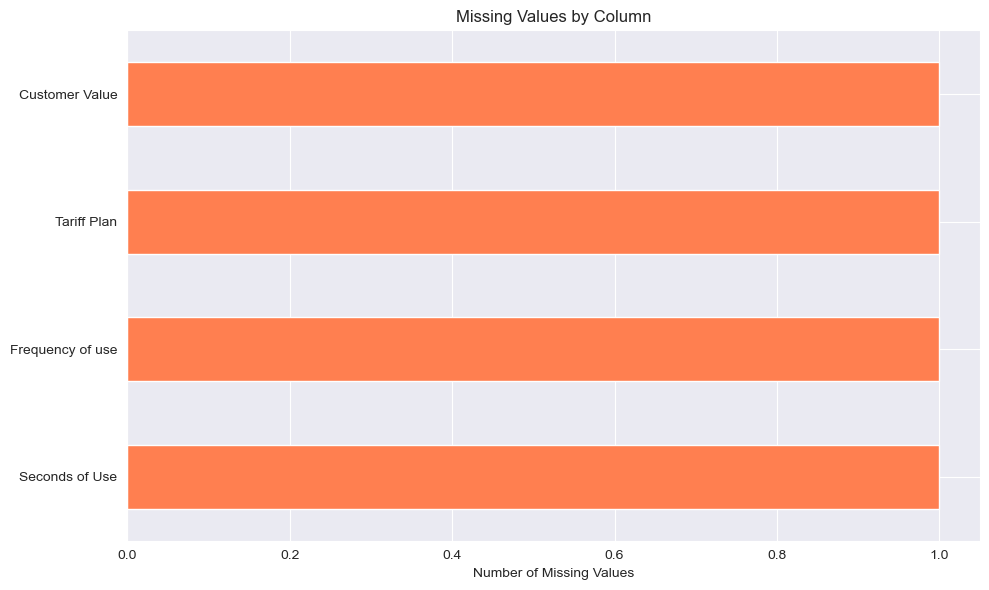

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0]

# Print results
print("Missing Values:")
print(missing)
print(f"\nTotal missing: {missing.sum()}")

# Simple bar chart
if len(missing) > 0:
    missing.plot(kind='barh', color='coral', figsize=(10, 6))
    plt.xlabel('Number of Missing Values')
    plt.title('Missing Values by Column')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values!")

## Check duplicates

In [6]:
print(f'Shape of dataset before dropping duplicated rows is: {df.shape}')

df = df.drop_duplicates()

print(f'Shape of dataset after dropping duplicated rows is: {df.shape}')

Shape of dataset before dropping duplicated rows is: (3152, 14)
Shape of dataset after dropping duplicated rows is: (2852, 14)


300 exact duplicate rows were removed (3,152 → 2,852). Keeping them would let the same customer appear in both the training and test sets and inflate the scores.

## Removing Missing Values

In [7]:
print(" Before removing missing values ")
print(df.isna().sum())
df = df.dropna()
print(" After removing missing values ")
print(df.isna().sum())

 Before removing missing values 
Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             1
Frequency of use           1
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                1
Status                     0
Age                        0
Customer Value             1
Churn                      0
dtype: int64
 After removing missing values 
Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64


We have a small number of missing values, so we drop 2 rows

## Checking for Outliers

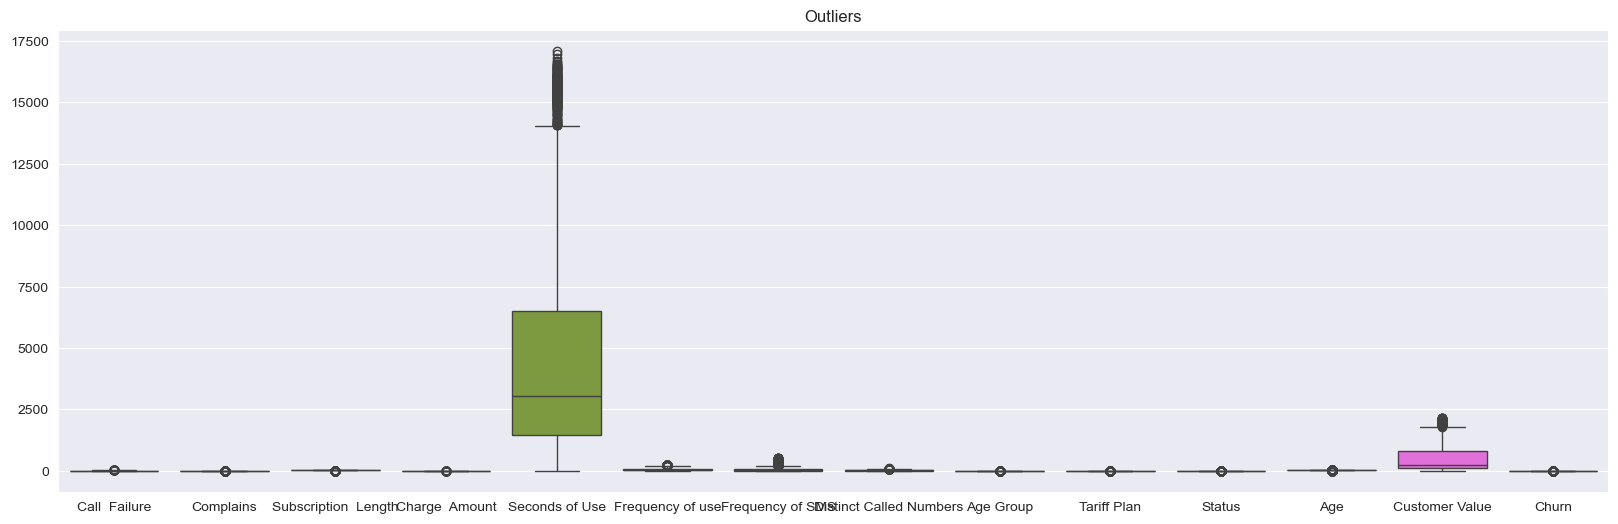

In [8]:
plt.figure(figsize = (20,6))
sns.boxplot(data = df)
plt.title("Outliers")
plt.show()

# EDA

In [9]:
df['Churn'].value_counts()

Churn
0    2404
1     446
Name: count, dtype: int64

Checking how many values we have for churn and not churn in the whole dataset

1 - client left
0 - no

In [10]:
df.columns

Index(['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value', 'Churn'],
      dtype='object')

In [11]:
df.dtypes

Call  Failure                int64
Complains                    int64
Subscription  Length         int64
Charge  Amount               int64
Seconds of Use             float64
Frequency of use           float64
Frequency of SMS             int64
Distinct Called Numbers      int64
Age Group                    int64
Tariff Plan                float64
Status                       int64
Age                          int64
Customer Value             float64
Churn                        int64
dtype: object

We have only numeric data so we don't need to convert anything

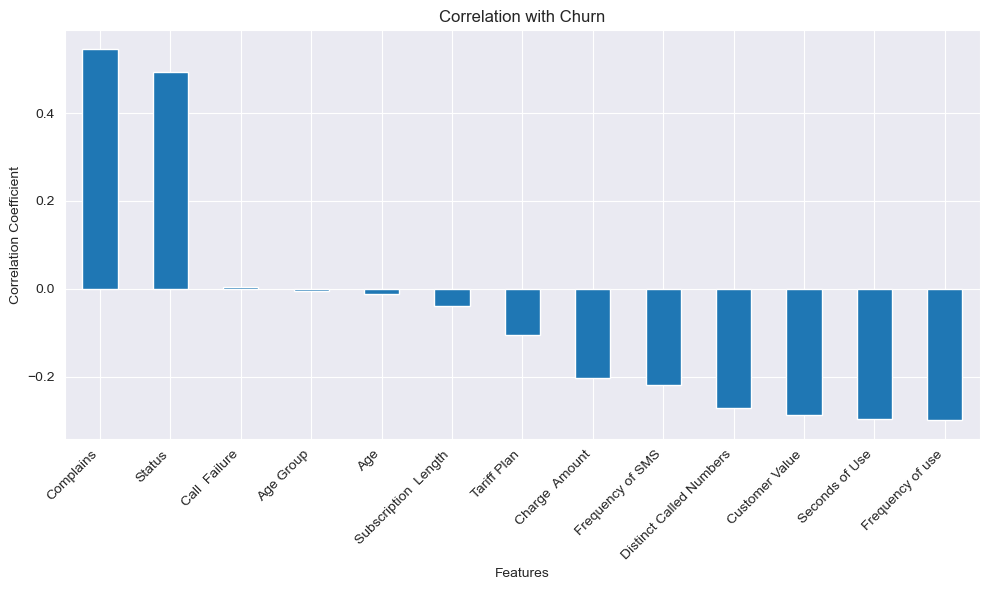

In [12]:
correlations = df.corr()['Churn'].drop('Churn').sort_values(ascending=False)

plt.figure(figsize=(10, 6))
correlations.plot(kind='bar')
plt.title('Correlation with Churn')
plt.ylabel('Correlation Coefficient')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

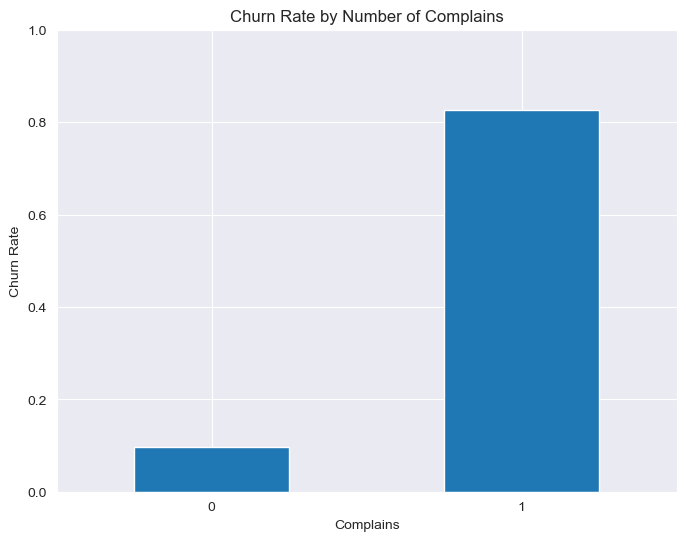

In [13]:
churn_by_complains = df.groupby('Complains')['Churn'].mean()

plt.figure(figsize=(8, 6))
churn_by_complains.plot(kind='bar')
plt.title('Churn Rate by Number of Complains')
plt.ylabel('Churn Rate')
plt.xlabel('Complains')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

In [14]:
df.corr()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
Call Failure,1.000000,0.149564,0.177206,0.585442,0.495463,0.567096,-0.031926,0.498604,0.049340,0.187537,-0.094090,0.043799,0.110228,0.003310
Complains,0.149564,1.000000,-0.019229,-0.035887,-0.108934,-0.095519,-0.114729,-0.061314,0.015761,0.002461,0.282928,-0.000400,-0.136989,0.546055
Subscription Length,0.177206,-0.019229,1.000000,0.084275,0.127184,0.109148,0.080530,0.099215,0.030078,-0.160538,0.144235,0.005900,0.113184,-0.037984
Charge Amount,0.585442,-0.035887,0.084275,1.000000,0.443585,0.372646,0.085781,0.413897,0.282761,0.321193,-0.353311,0.283466,0.161852,-0.201662
Seconds of Use,0.495463,-0.108934,0.127184,0.443585,1.000000,0.945144,0.093073,0.671973,0.015253,0.127793,-0.449660,0.019383,0.408536,-0.295999
Frequency of use,0.567096,-0.095519,0.109148,0.372646,0.945144,1.000000,0.090712,0.731204,-0.039523,0.199873,-0.440601,-0.031574,0.394647,-0.298608
Frequency of SMS,-0.031926,-0.114729,0.080530,0.085781,0.093073,0.090712,1.000000,0.069717,-0.056859,0.193785,-0.288049,-0.093235,0.922852,-0.218894
Distinct Called Numbers,0.498604,-0.061314,0.099215,0.413897,0.671973,0.731204,0.069717,1.000000,0.015562,0.167037,-0.393052,0.049187,0.275447,-0.270343
Age Group,0.049340,0.015761,0.030078,0.282761,0.015253,-0.039523,-0.056859,0.015562,1.000000,-0.153496,0.020048,0.960877,-0.193461,-0.005891
Tariff Plan,0.187537,0.002461,-0.160538,0.321193,0.127793,0.199873,0.193785,0.167037,-0.153496,1.000000,-0.163083,-0.120429,0.249999,-0.106000


We only have numerical values so we dont need to specify  numeric_only=true in corr function

<Axes: >

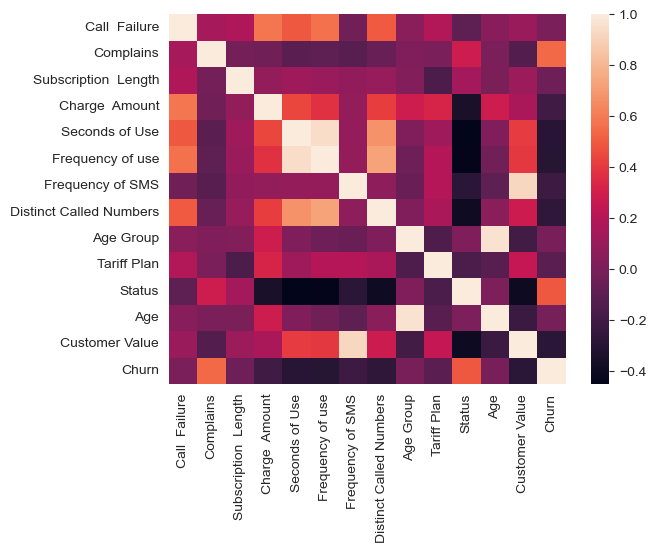

In [15]:
sns.heatmap(df.corr(), annot=False)

Keeping the annot parameter false so we dont have numerical values written on top of boxes

## Histogram (Numeric Values)

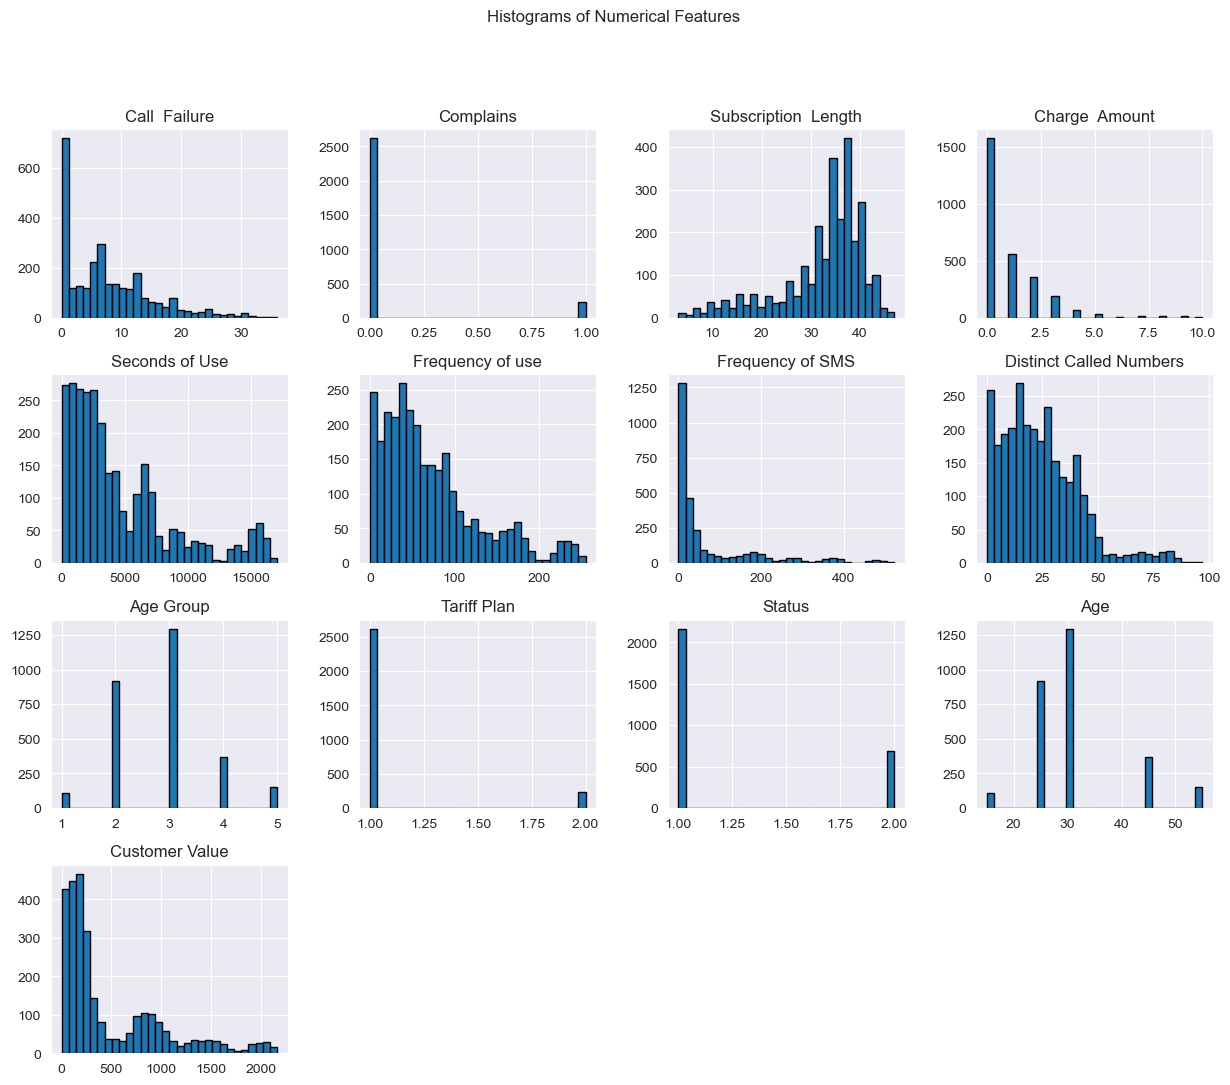

In [16]:
num_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
num_cols.remove('Churn')

df[num_cols].hist(figsize=(15,12), bins=30, edgecolor='black')
plt.suptitle("Histograms of Numerical Features")
plt.show()

## Boxplot Comparison (Churn and Numerical Variables)

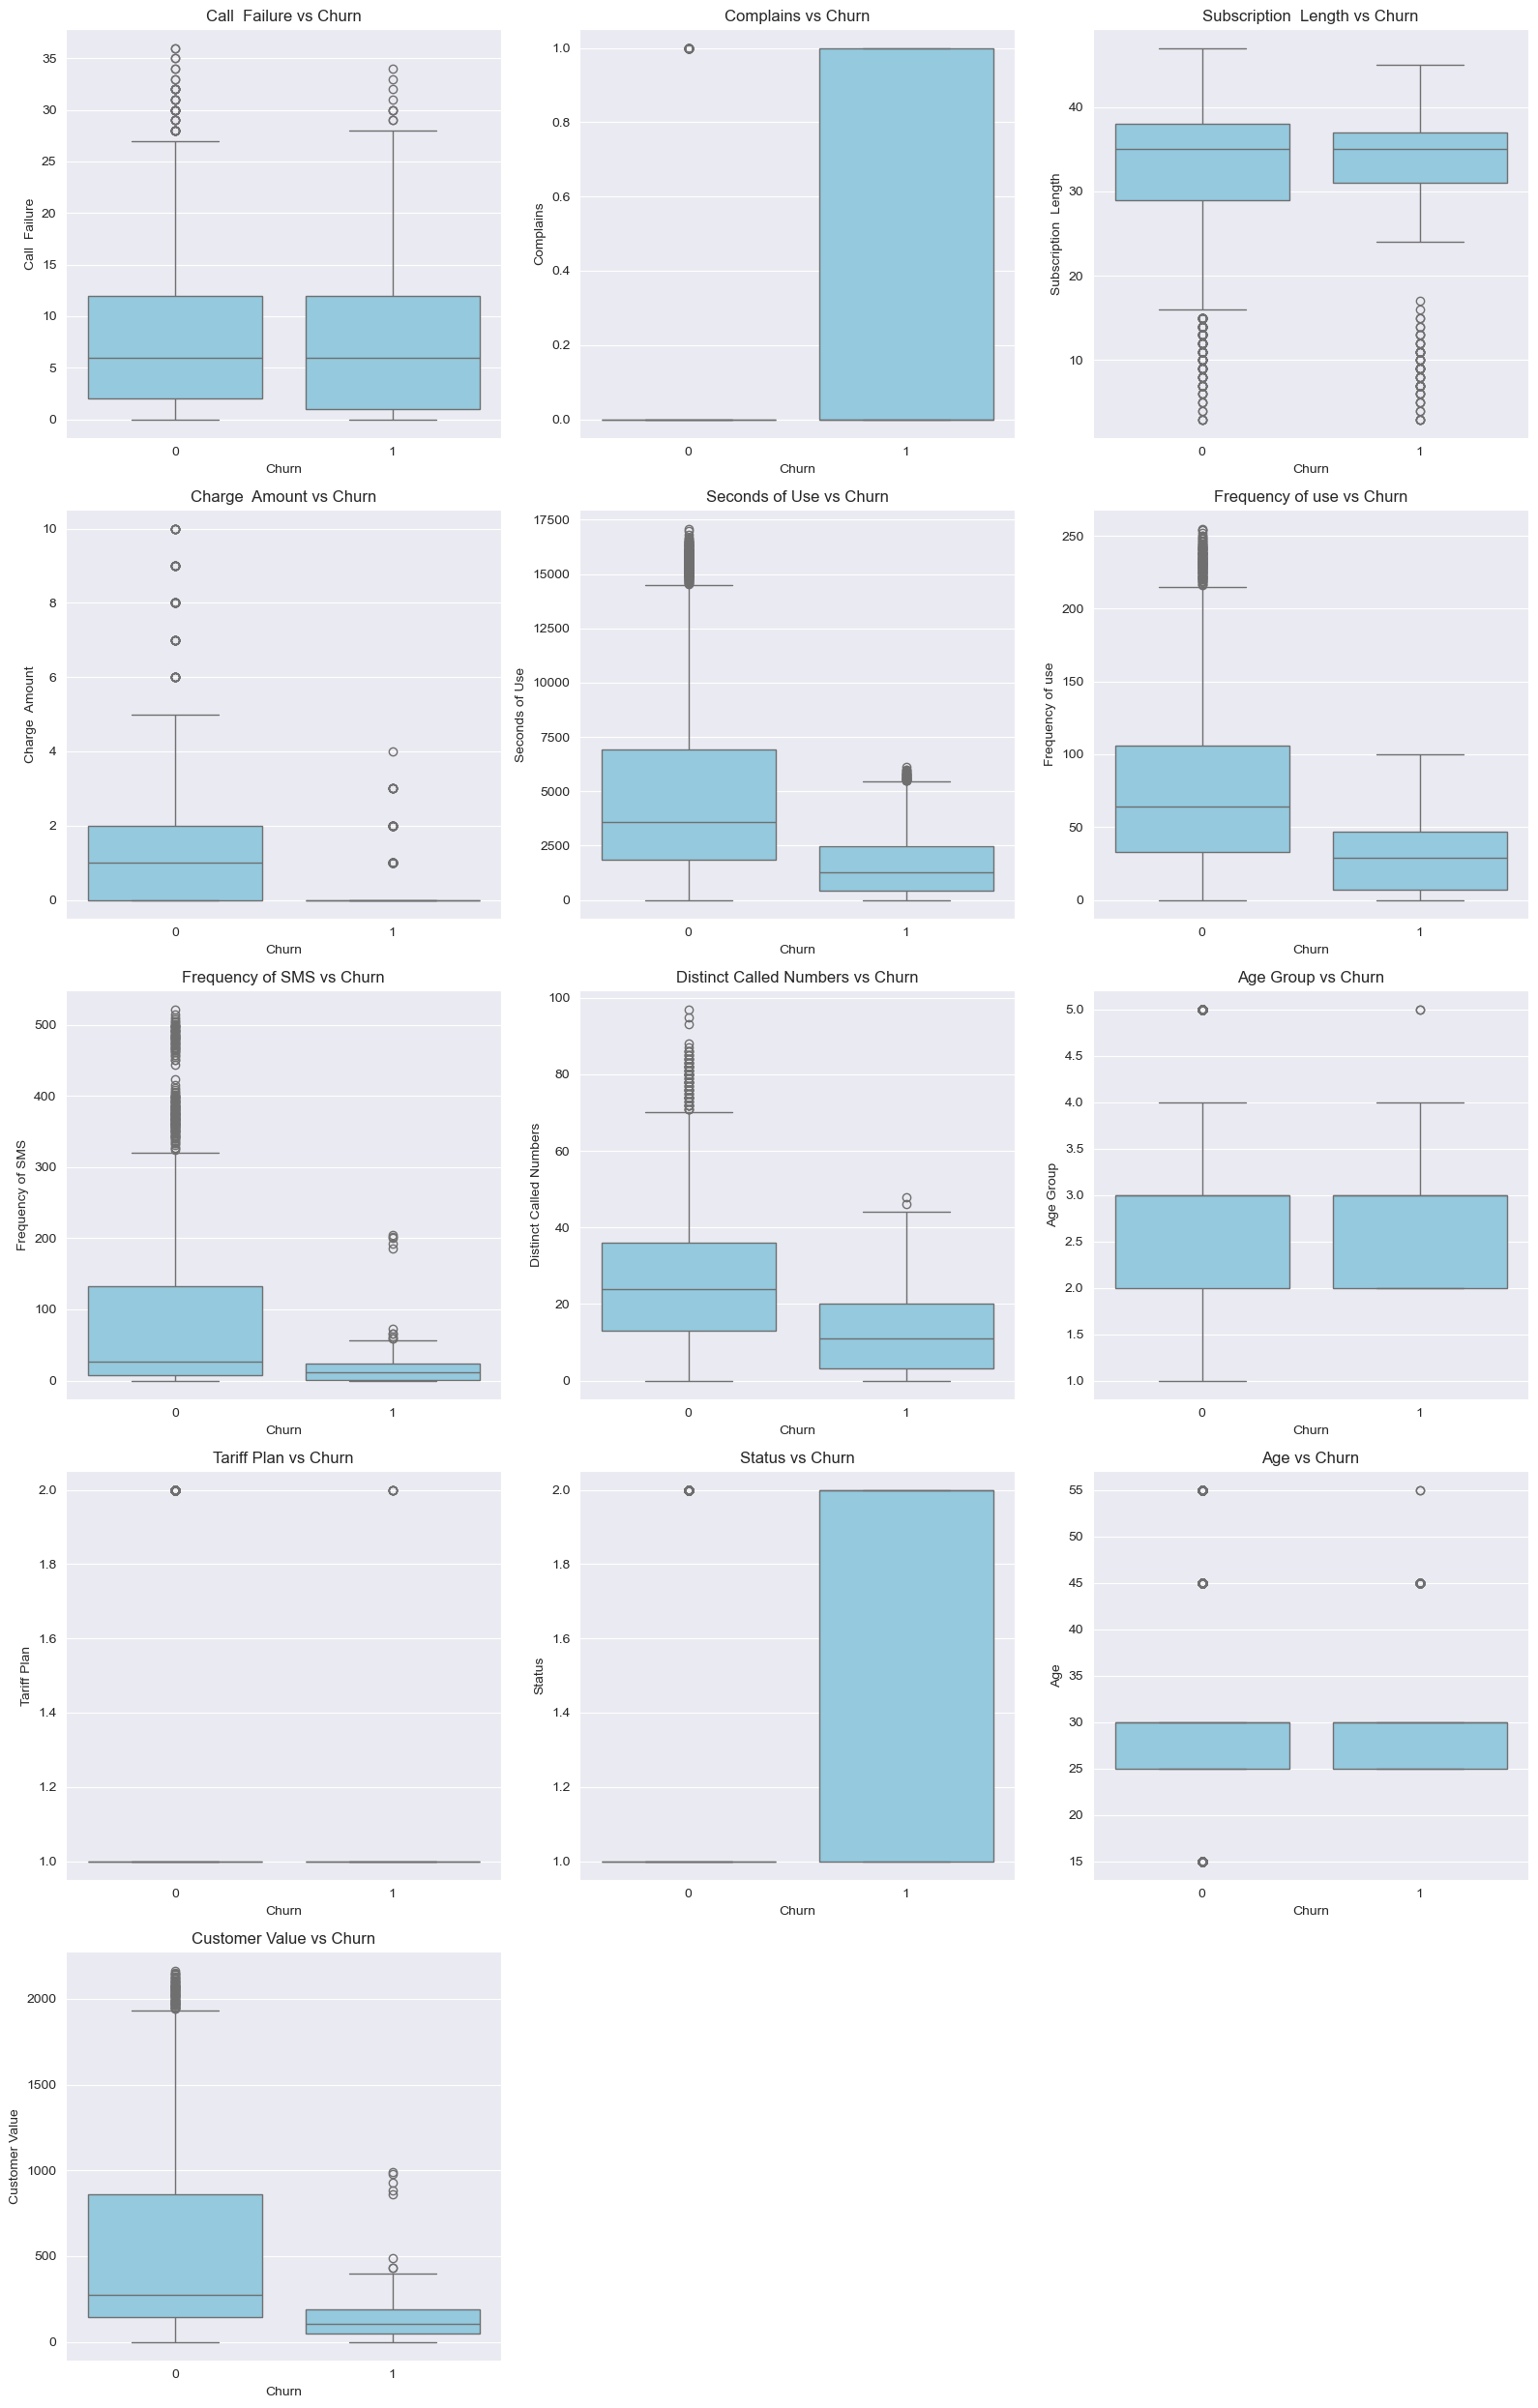

In [17]:
import math

n = len(num_cols)
cols = 3
rows = math.ceil(n / cols)

plt.figure(figsize=(16, 5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x='Churn', y=col, data=df, color='skyblue')
    plt.title(f"{col} vs Churn")

plt.tight_layout()
plt.show()



## Correlation Heatmap

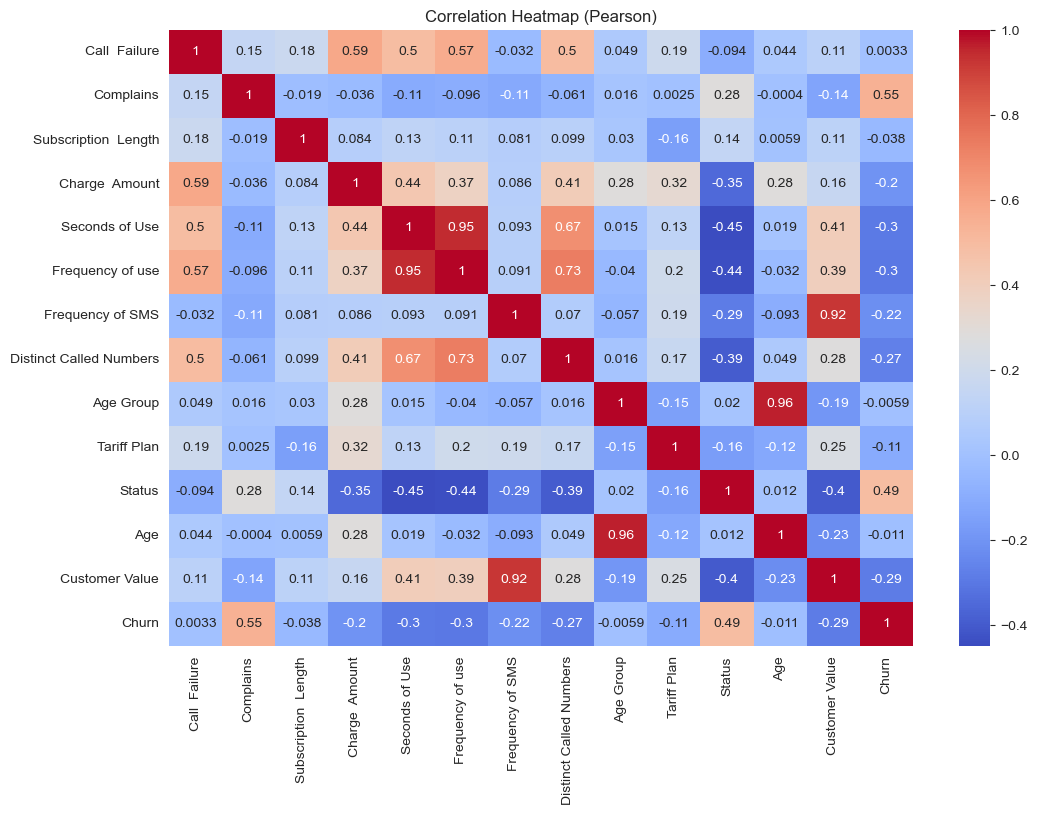

In [18]:
plt.figure(figsize=(12,8))
sns.heatmap(df[num_cols + ['Churn']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap (Pearson)")
plt.show()

This heatmap shows how each numerical feature is linearly related to all other numerical features, including Churn, with values between -1 and 1. Red = positive correlation, blue = negative correlation.

## Scatterplots

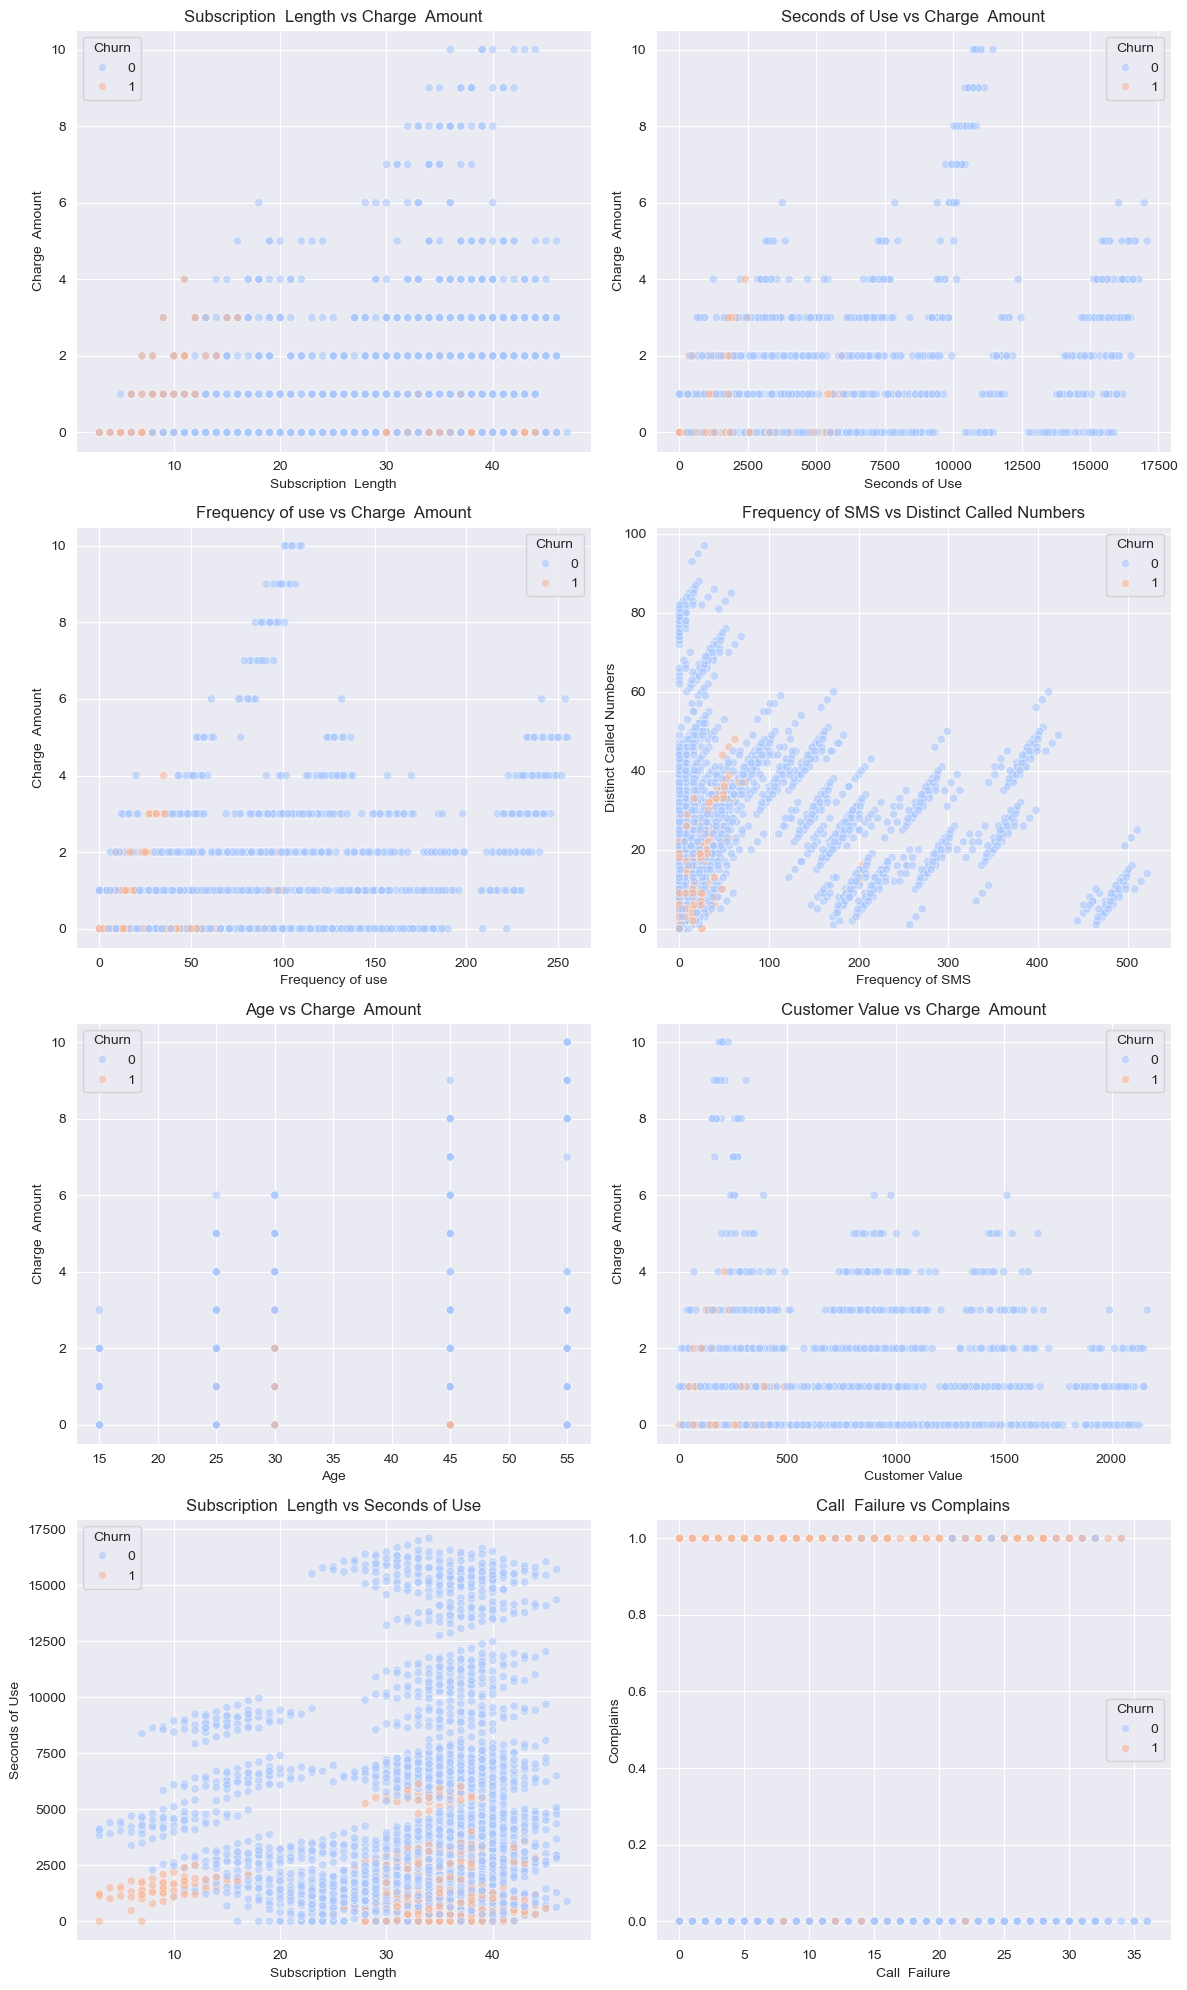

In [19]:
import math

df.columns = df.columns.str.strip()

pairs = [
    ('Subscription  Length', 'Charge  Amount'),
    ('Seconds of Use', 'Charge  Amount'),
    ('Frequency of use', 'Charge  Amount'),
    ('Frequency of SMS', 'Distinct Called Numbers'),
    ('Age', 'Charge  Amount'),
    ('Customer Value', 'Charge  Amount'),
    ('Subscription  Length', 'Seconds of Use'),
    ('Call  Failure', 'Complains')
]

# Calculate rows and columns for subplots
rows = math.ceil(len(pairs) / 2)
cols = 2

plt.figure(figsize=(12, 5 * rows))

for i, (x, y) in enumerate(pairs, 1):
    plt.subplot(rows, cols, i)
    sns.scatterplot(data=df, x=x, y=y, hue='Churn', palette='coolwarm', alpha=0.6)
    plt.title(f"{x} vs {y}")

plt.tight_layout()
plt.show()



## Pairplot

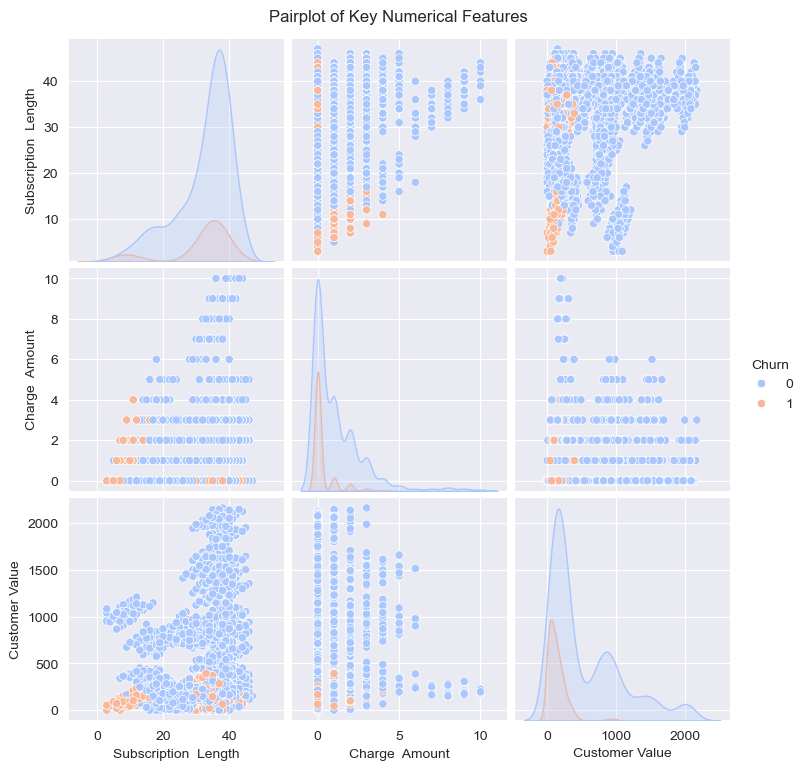

In [20]:
# Select a smaller subset for clearer visualization
selected_cols = ['Subscription  Length', 'Charge  Amount', 'Customer Value', 'Churn']

sns.pairplot(df[selected_cols], hue='Churn', palette='coolwarm')
plt.suptitle("Pairplot of Key Numerical Features", y=1.02)
plt.show()

## KDE Plot

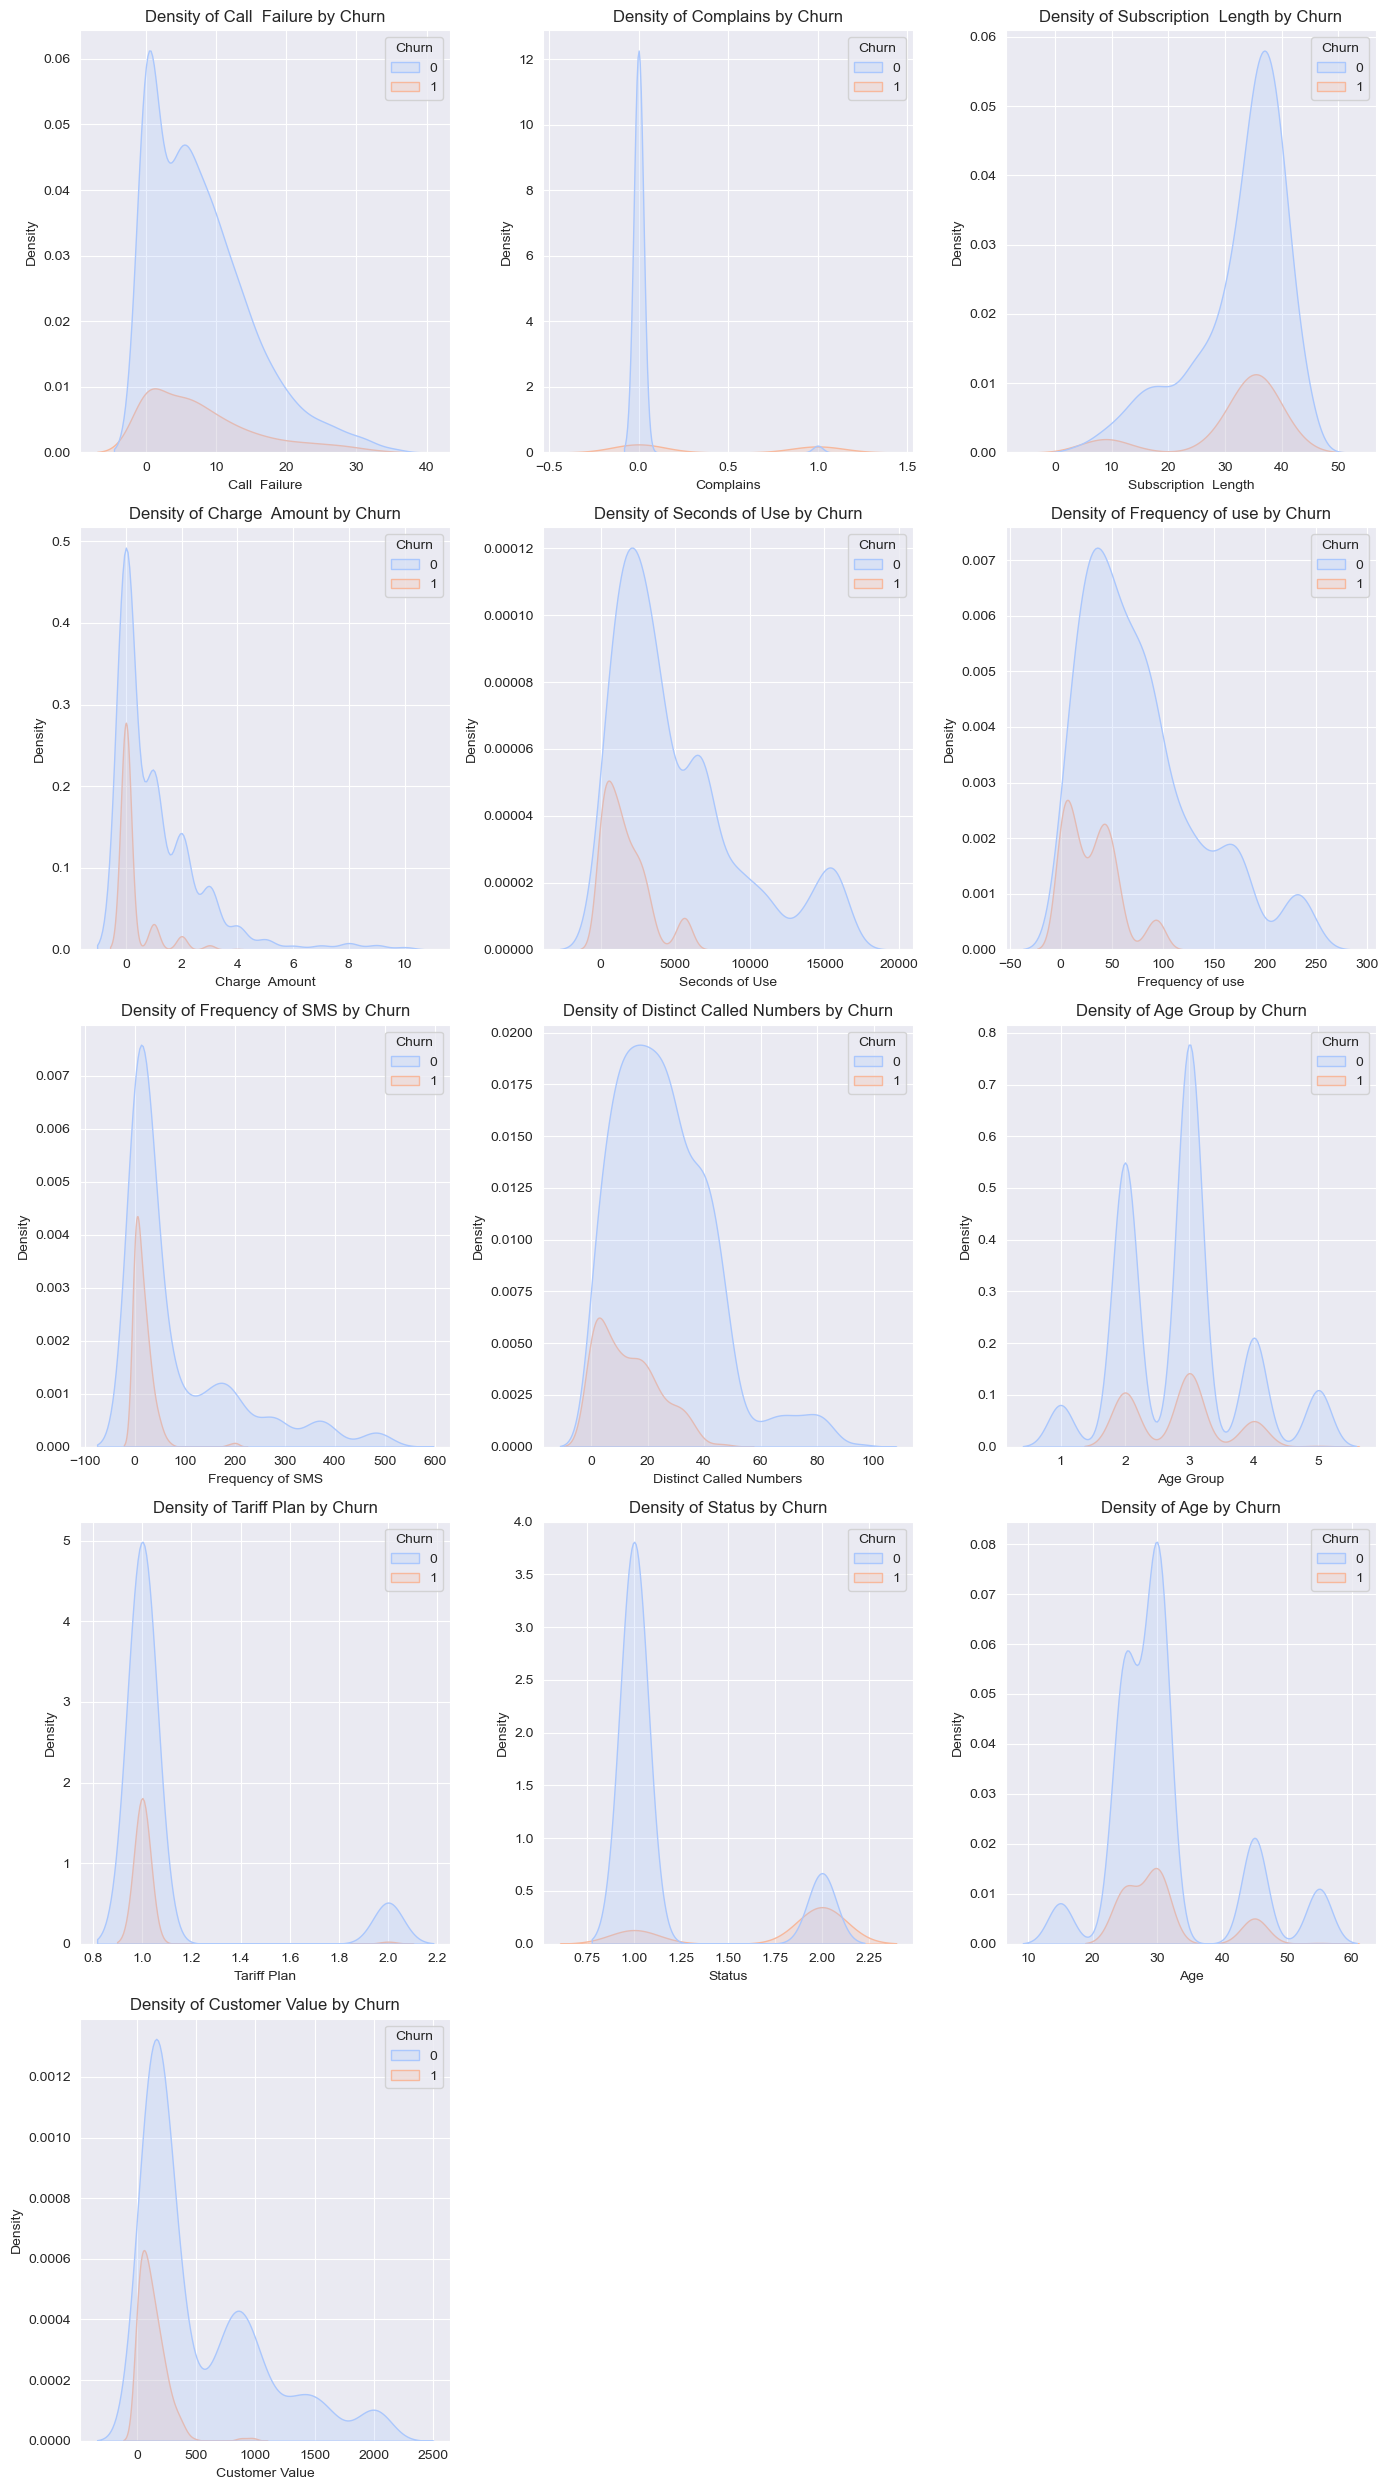

In [21]:
# Dynamically calculate the grid size based on number of columns
num_cols_count = len(num_cols)
cols_per_row = 3
rows = math.ceil(num_cols_count / cols_per_row)

plt.figure(figsize=(14, 5 * rows))

for i, col in enumerate(num_cols):
    plt.subplot(rows, cols_per_row, i+1)
    sns.kdeplot(data=df, x=col, hue="Churn", fill=True, palette='coolwarm')
    plt.title(f"Density of {col} by Churn")

plt.tight_layout()
plt.show()

In [22]:
X = df[['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount',
       'Seconds of Use', 'Frequency of use', 'Frequency of SMS',
       'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age',
       'Customer Value']] .values
X[0:5]

array([[8.00000e+00, 0.00000e+00, 3.80000e+01, 0.00000e+00, 4.37000e+03,
        7.10000e+01, 5.00000e+00, 1.70000e+01, 3.00000e+00, 1.00000e+00,
        1.00000e+00, 3.00000e+01, 1.97640e+02],
       [0.00000e+00, 0.00000e+00, 3.90000e+01, 0.00000e+00, 3.18000e+02,
        5.00000e+00, 7.00000e+00, 4.00000e+00, 2.00000e+00, 1.00000e+00,
        2.00000e+00, 2.50000e+01, 4.60350e+01],
       [1.00000e+01, 0.00000e+00, 3.70000e+01, 0.00000e+00, 2.45300e+03,
        6.00000e+01, 3.59000e+02, 2.40000e+01, 3.00000e+00, 1.00000e+00,
        1.00000e+00, 3.00000e+01, 1.53652e+03],
       [1.00000e+01, 0.00000e+00, 3.80000e+01, 0.00000e+00, 4.19800e+03,
        6.60000e+01, 1.00000e+00, 3.50000e+01, 1.00000e+00, 1.00000e+00,
        1.00000e+00, 1.50000e+01, 2.40020e+02],
       [3.00000e+00, 0.00000e+00, 3.80000e+01, 0.00000e+00, 2.39300e+03,
        5.80000e+01, 2.00000e+00, 3.30000e+01, 1.00000e+00, 1.00000e+00,
        1.00000e+00, 1.50000e+01, 1.45805e+02]])

In [23]:
y = df['Churn'].values
y[0:5]

array([0, 0, 0, 0, 0])

In [24]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000,2850.000000
mean,7.802456,0.080702,32.452982,0.974737,4534.243158,70.484912,73.789825,23.870526,2.835088,1.080351,1.240000,31.077193,474.990367,0.156491
std,7.326172,0.272424,8.723075,1.550618,4199.712303,57.401512,112.062397,17.193929,0.893503,0.271883,0.427158,8.861934,514.442198,0.363384
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,29.000000,0.000000,1458.750000,28.000000,7.000000,11.000000,2.000000,1.000000,1.000000,25.000000,117.527500,0.000000
50%,6.000000,0.000000,35.000000,0.000000,3041.000000,54.500000,22.000000,21.000000,3.000000,1.000000,1.000000,30.000000,232.520000,0.000000
75%,12.000000,0.000000,38.000000,2.000000,6500.000000,96.000000,88.000000,34.000000,3.000000,1.000000,1.000000,30.000000,790.080000,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


## Call-related Features:
a) Call Failure:

Mean: 7.63 failed calls on average

Median (50%): 6 failed calls

Maximum: 36 failed calls suggests that while most customers experience a moderate number of call failures, some outliers have significantly higher failure rates.


b) Complains:

Mean: 0.077 complaints

75% of customers have 0 complaints

Maximum: 1 complaint This indicates that formal complaints are rare, with most customers not complaining at all.

c) Subscription Length:

Mean: 32.54

Median: 35 months

Range: 3 to 47 months This shows that the average customer has been subscribed for about 2.5 years, with some long-term customers of up to 4 years.

## Usage Statistics:

a) Seconds of Use:

Mean: 4,472 seconds (about 74.5 minutes)

Median: 2,990 seconds (about 50 minutes)

Maximum: 17,090 seconds (about 4.75 hours) Usage varies widely, with some customers using the service much more heavily than others.

b) Frequency of Use:

Mean: 69.46 times

Median: 54 times

Maximum: 255 times This likely represents how often customers use the service in a given period.

c) Frequency of SMS:

Mean: 73.17 SMS

Median: 21 SMS

Maximum: 522 SMS SMS usage is highly skewed, with some customers sending a very high number of messages.

## Customer Information:

a) Distinct Called Numbers:

Mean: 23.51

Median: 21

Range: 0 to 97 This shows the diversity in customers’ calling patterns.

b) Age Group:

Mean: 2.83

Range: 1 to 5 Customers are categorized into 5 age groups, with the average falling between groups 2 and 3.

c) Tariff Plan:

Mean: 1.08

Maximum: 2 Most customers are on tariff plan 1, with some on plan 2.

d) Status:

Mean: 1.25

Range: 1 to 2 This could represent customer status categories (e.g., regular vs. premium).

e) Age:

Mean: 31 years

Range: 15 to 55 years The customer base spans from teenagers to middle-aged adults.

## Value and Churn:

a) Customer Value:

Mean: 470.97

Median: 228.48

Range: 0 to 2,165.28 This metric (possibly in local currency) shows high variability in customer value, with some customers being significantly more valuable than others.

b) Churn:

Mean: 0.157 (15.7% churn rate)

Range: 0 to 1 This binary variable indicates whether a customer has churned (1) or not (0). The 15.7% churn rate is significant and justifies the need for predictive modelling to reduce churn.

## Churn Rate by Complains

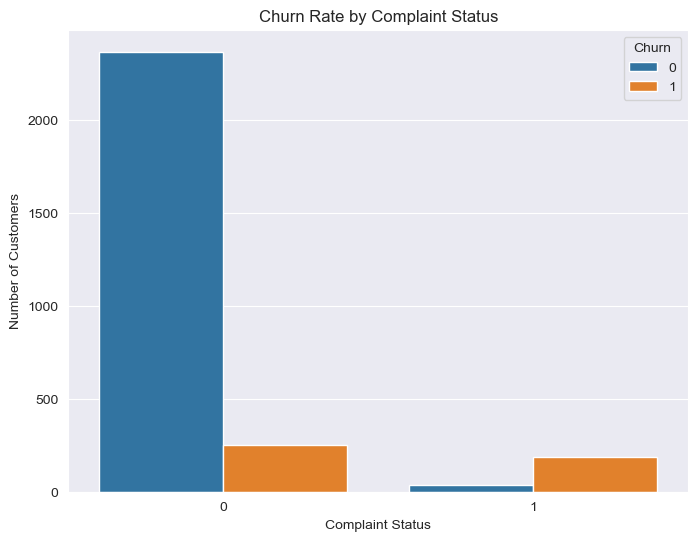

Churn rate for customers who complained: 0.83
Churn rate for customers who did not complain: 0.10


In [25]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Complains', hue='Churn', data=df)
plt.title('Churn Rate by Complaint Status')
plt.xlabel('Complaint Status')
plt.ylabel('Number of Customers')
plt.legend(title='Churn')
plt.show()

complaint_churn_rate = df[df['Complains'] == 1]['Churn'].mean()
no_complaint_churn_rate = df[df['Complains'] == 0]['Churn'].mean()

print(f"Churn rate for customers who complained: {complaint_churn_rate:.2f}")
print(f"Churn rate for customers who did not complain: {no_complaint_churn_rate:.2f}")



## Churn Rate by Age

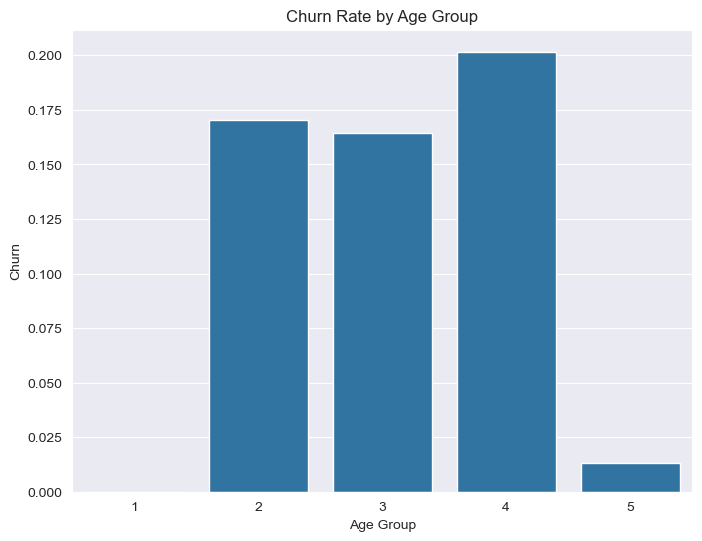

In [26]:
plt.figure(figsize=(8,6))
sns.barplot(x='Age Group',y='Churn',data = df, errorbar=None)
plt.title('Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn')
plt.show()

## Feature Engineering

In [27]:
features_call = ['Call  Failure','Complains','Subscription  Length']
features_usage = ['Seconds of Use','Frequency of use','Frequency of SMS']
features_customer = ['Distinct Called Numbers','Age Group','Tariff Plan','Status', 'Age', 'Customer Value']
features_target = ['Churn']

df_final = df[features_call+features_usage+features_customer+ features_usage +features_target]


## Dataset Modelling & Utility Functions.

In [28]:
sns.set(style="whitegrid")

#plot function to plot different models and thier results
#Plot confusion matrix, ROC curve, and precision-recall curve
def plot_evaluation_curves(model_name, y_test, y_pred, y_proba):

    plt.figure(figsize=(18, 5))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.subplot(1, 3, 1)
    plt.imshow(cm, cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.colorbar()
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=12)

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.subplot(1, 3, 2)
    plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(f"{model_name} - ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()

    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    plt.subplot(1, 3, 3)
    plt.plot(recall, precision, linewidth=2)
    plt.title(f"{model_name} - Precision-Recall Curve")
    plt.xlabel("Recall")
    plt.ylabel("Precision")

    plt.tight_layout()
    plt.show()

#Plot cross-validation results comparing train and test scores
def plot_cv_comparison(cv_results, model_name):

    metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    train_means = [cv_results[f'train_{m}'].mean() for m in metrics]
    test_means = [cv_results[f'test_{m}'].mean() for m in metrics]
    test_stds = [cv_results[f'test_{m}'].std() for m in metrics]

    x = np.arange(len(metrics))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, train_means, width, label='Train', alpha=0.8)
    ax.bar(x + width/2, test_means, width, label='Test (CV)', alpha=0.8, yerr=test_stds, capsize=5)

    ax.set_xlabel('Metrics', fontsize=12)
    ax.set_ylabel('Scores', fontsize=12)
    ax.set_title(f'{model_name} - Cross-Validation Results', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([m.upper() for m in metrics])
    ax.legend()
    ax.set_ylim([0, 1.1])
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


#Print formatted cross-validation results
def print_cv_results(cv_results, model_name):

    print("--")
    print(f"{model_name} - CROSS-VALIDATION RESULTS (5-Fold Stratified)")
    print("--")
    for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
        train_score = cv_results[f'train_{metric}'].mean()
        train_std = cv_results[f'train_{metric}'].std()
        test_score = cv_results[f'test_{metric}'].mean()
        test_std = cv_results[f'test_{metric}'].std()
        print(f"{metric.upper():12} - Train: {train_score:.4f} (±{train_std:.4f}) | "
              f"CV Test: {test_score:.4f} (±{test_std:.4f})")



print("--")
print("Data Preparation")
print("--")

X = df_final.drop(columns='Churn')
y = df_final['Churn']

# Stratified split to maintain class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Remove duplicate columns if any (again checking)
X_train = X_train.loc[:, ~X_train.columns.duplicated()]
X_test = X_test.loc[:, ~X_test.columns.duplicated()]

print(f"\nTraining set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")
print(f"\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))
print(f"\nClass distribution in test set:")
print(y_test.value_counts(normalize=True))

# Scaling for KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define Stratified K-Fold for all models
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store results for final comparison
results_summary = []




--
Data Preparation
--

Training set size: (2280, 12)
Test set size: (570, 12)

Class distribution in training set:
Churn
0    0.843421
1    0.156579
Name: proportion, dtype: float64

Class distribution in test set:
Churn
0    0.84386
1    0.15614
Name: proportion, dtype: float64


-> plot_evaluation_curves: Shows confusion matrix, ROC curve, and precision-recall curve to understand model performance. Helps visualize how well the model predicts and separates classes.

-> plot_cv_comparison: Plots training vs cross-validation scores. To check if the model is overfitting (high train score, low test score) or underfitting.

-> print_cv_results: Prints metrics like accuracy, precision, recall, F1, and ROC AUC. Gives a clear, quick summary of model performance across folds.

-> Separate features (X) and target (y).

-> Split into training and testing sets with stratification to Ensures class distribution is balanced, so evaluation is fair.

-> Standardize features using StandardScaler (mean 0, std 1). Important for models like KNN that rely on distances; ensures all features contribute equally.

-> Use Stratified K-Fold (5 splits) to test model on multiple subsets. Gives a reliable estimate of performance and maintains class balance.

-> results_summary list stores metrics of all models which makes it easy to compare different models and select the best one

## ML Models

## Decision Tree Classifier

--
MODEL 1: DECISION TREE CLASSIFIER
--
Fitting 5 folds for each of 1920 candidates, totalling 9600 fits

Best Parameters: {'criterion': 'gini', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
Best CV F1 Score: 0.8096
--
Decision Tree - CROSS-VALIDATION RESULTS (5-Fold Stratified)
--
ACCURACY     - Train: 0.9963 (±0.0005) | CV Test: 0.9404 (±0.0061)
PRECISION    - Train: 1.0000 (±0.0000) | CV Test: 0.8104 (±0.0265)
RECALL       - Train: 0.9762 (±0.0035) | CV Test: 0.8096 (±0.0235)
F1           - Train: 0.9879 (±0.0018) | CV Test: 0.8096 (±0.0183)
ROC_AUC      - Train: 0.9999 (±0.0000) | CV Test: 0.8978 (±0.0107)


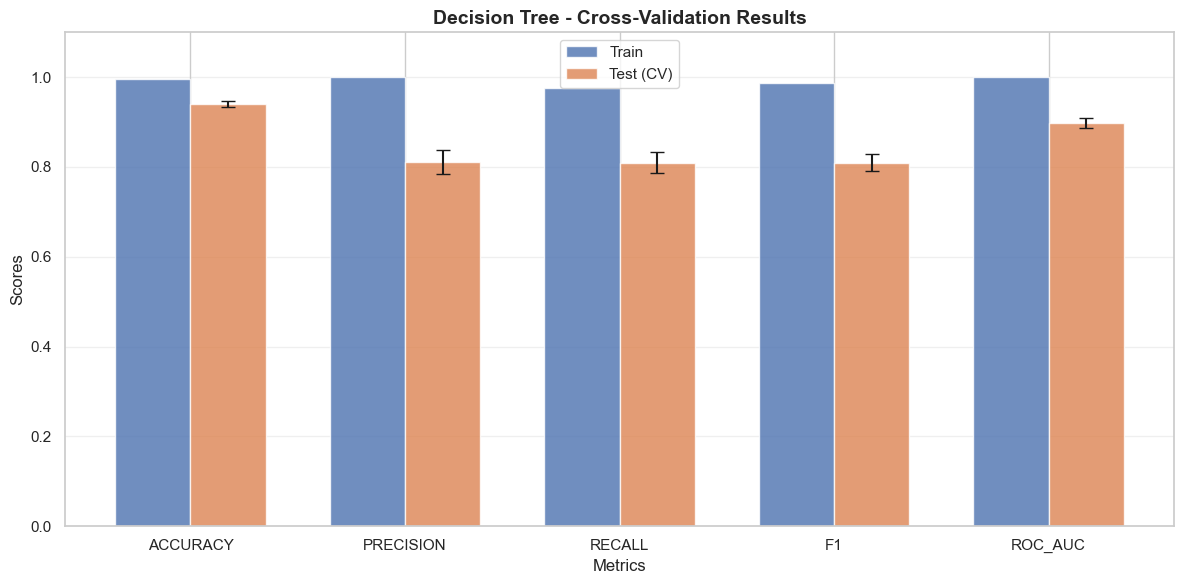

--
DECISION TREE - FINAL TEST SET EVALUATION
--
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       481
           1       0.80      0.81      0.80        89

    accuracy                           0.94       570
   macro avg       0.88      0.89      0.88       570
weighted avg       0.94      0.94      0.94       570



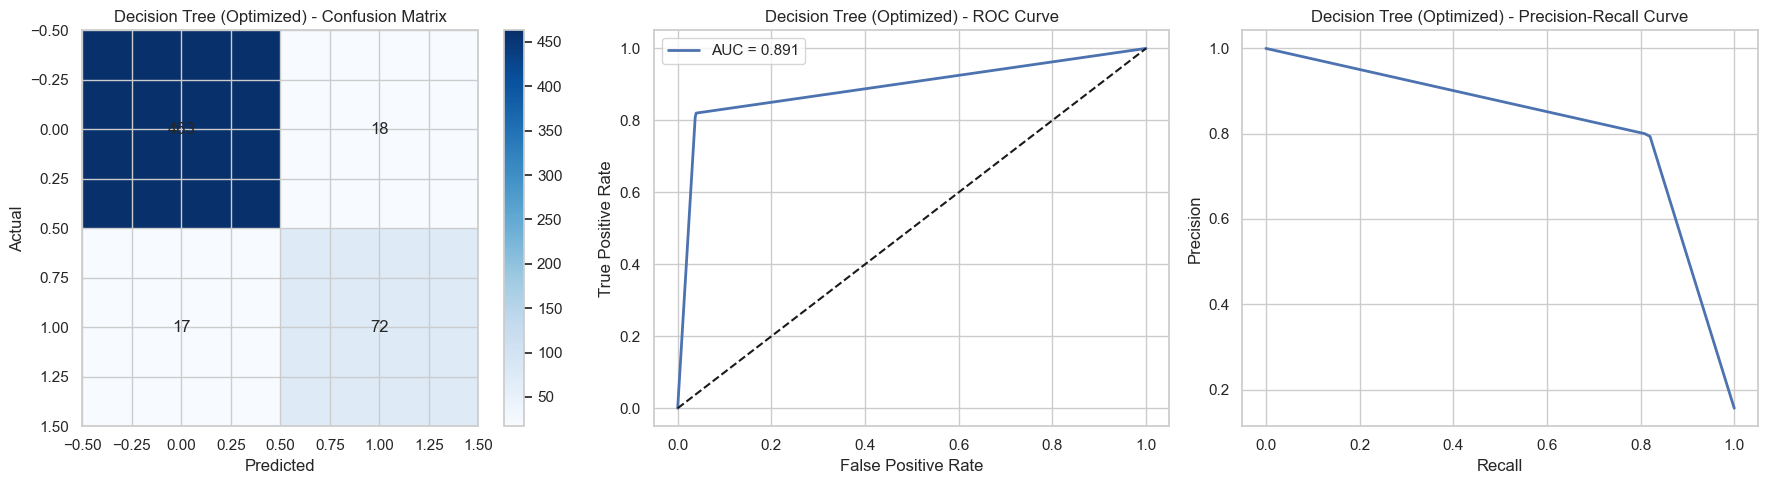

In [33]:
print("--")
print("MODEL 1: DECISION TREE CLASSIFIER")
print("--")

# Parameter grid
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 7, 8, 10, None],
    'min_samples_split': [2, 4, 6, 8, 10],
    'min_samples_leaf': [1, 2, 4, 6],
    'max_features': ['sqrt', 'log2', None],
    'splitter': ['best', 'random']
}

dtree = DecisionTreeClassifier(random_state=42)

grid_dt = GridSearchCV(
    estimator=dtree,
    param_grid=param_grid_dt,
    cv=skf,  # Stratified K-Fold
    scoring='f1',
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

#Performing Grid Search with 5-Fold Stratified CV
grid_dt.fit(X_train, y_train)

print(f"\nBest Parameters: {grid_dt.best_params_}")
print(f"Best CV F1 Score: {grid_dt.best_score_:.4f}")

# Get best model and perform detailed CV evaluation
best_dt = grid_dt.best_estimator_
cv_results_dt = cross_validate(
    best_dt, X_train, y_train, cv=skf,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    return_train_score=True, n_jobs=-1
)

print_cv_results(cv_results_dt, "Decision Tree")
plot_cv_comparison(cv_results_dt, "Decision Tree")

# Final evaluation on test set
best_dt.fit(X_train, y_train)
y_pred_dt = best_dt.predict(X_test)
y_proba_dt = best_dt.predict_proba(X_test)[:, 1]

print("--")
print("DECISION TREE - FINAL TEST SET EVALUATION")
print("--")
print(classification_report(y_test, y_pred_dt))

plot_evaluation_curves("Decision Tree (Optimized)", y_test, y_pred_dt, y_proba_dt)

# Store results
results_summary.append({
    'Model': 'Decision Tree',
    'CV F1': cv_results_dt['test_f1'].mean(),
    'CV ROC-AUC': cv_results_dt['test_roc_auc'].mean(),
    'Test F1': f1_score(y_test, y_pred_dt),
    'Test ROC-AUC': roc_auc_score(y_test, y_proba_dt),
    'Test Accuracy': accuracy_score(y_test, y_pred_dt)
})



-> param_grid_dt: Defines different values for Decision Tree parameters like max_depth, criterion, min_samples_split, etc. Grid Search will test all combinations to find the hyperparameters for the model.

-> grid_dt : Uses GridSearchCV to try all parameter combinations. Uses 5-fold Stratified CV to test performance on different data splits. Uses F1 score as scoring metric.  Ensures we get the best-performing and most balanced model.

-> grid_dt.fit(X_train, y_train): Runs the grid search and finds the best parameters. Automatically chooses the best version of the Decision Tree.

-> cv_results_dt : Performs detailed evaluation with metrics (accuracy, precision, recall, F1, ROC-AUC). Gives a complete picture of model performance on training folds.

-> results_summary: Saves important metrics like F1, ROC-AUC, and accuracy. Allows comparison with other models later.

# Hyper parameters
-> criterion → Decides how the tree measures “impurity” at each split (Gini or Entropy). Helps find better-quality splits.

-> max_depth → Limits how deep the tree can grow. Prevents the model from overfitting by keeping the tree simpler.

-> min_samples_split → Minimum samples required to split a node. Higher values reduce unnecessary splits and make the model more stable.

-> min_samples_leaf → Minimum samples required in each leaf. Prevents tiny leaves and improves generalization.

-> max_features → Controls how many features the tree can use at each split. Reduces overfitting and increases model robustness.

-> splitter → Decides if the tree chooses the best split or a random split. Random splits add randomness that can reduce overfitting.


## KNN

--
MODEL 2: K-NEAREST NEIGHBORS (KNN)
--
Fitting 5 folds for each of 72 candidates, totalling 360 fits

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 3, 'p': 1, 'weights': 'distance'}
Best CV F1 Score: 0.8492
--
KNN - CROSS-VALIDATION RESULTS (5-Fold Stratified)
--
ACCURACY     - Train: 0.9963 (±0.0005) | CV Test: 0.9539 (±0.0091)
PRECISION    - Train: 1.0000 (±0.0000) | CV Test: 0.8696 (±0.0346)
RECALL       - Train: 0.9762 (±0.0035) | CV Test: 0.8320 (±0.0539)
F1           - Train: 0.9879 (±0.0018) | CV Test: 0.8492 (±0.0324)
ROC_AUC      - Train: 0.9999 (±0.0000) | CV Test: 0.9595 (±0.0173)


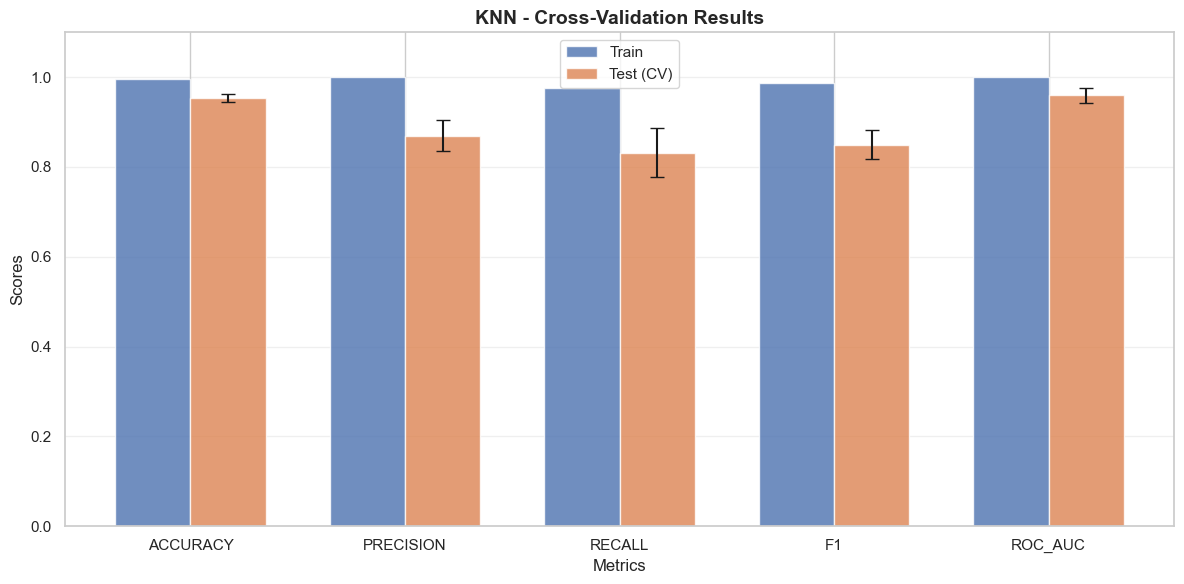

--
KNN - FINAL TEST SET EVALUATION
--
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       481
           1       0.86      0.88      0.87        89

    accuracy                           0.96       570
   macro avg       0.92      0.92      0.92       570
weighted avg       0.96      0.96      0.96       570



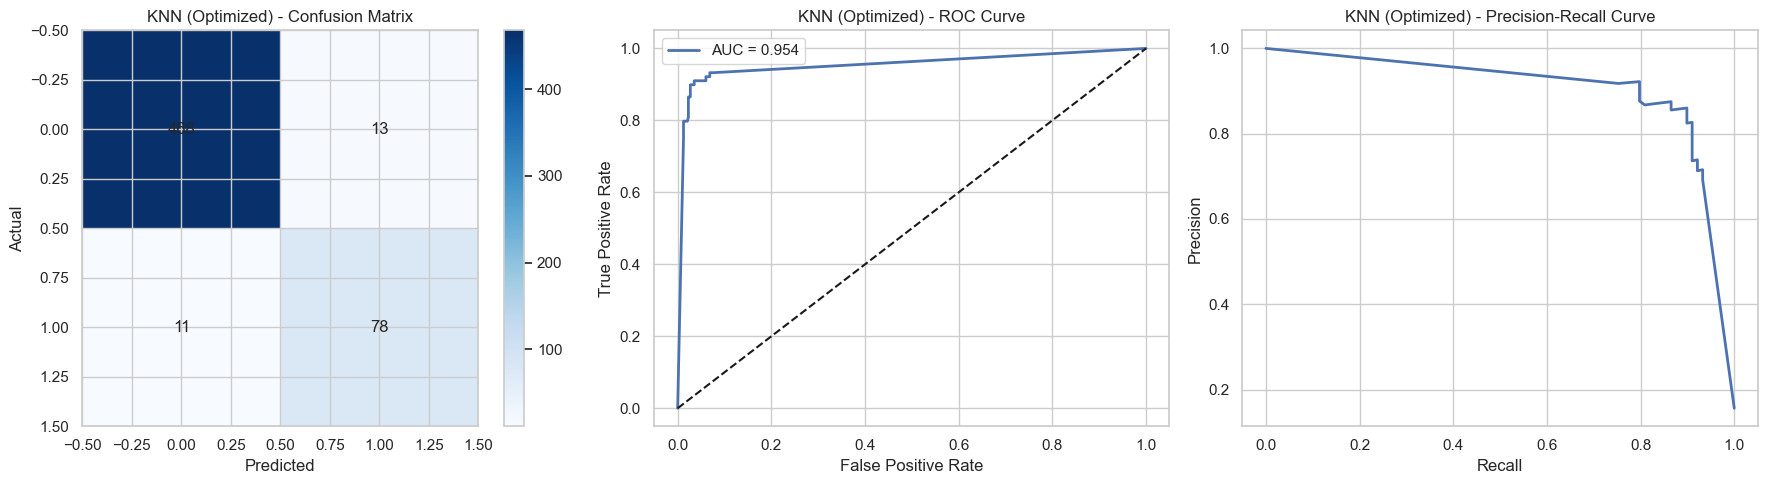

In [34]:
print("--")
print("MODEL 2: K-NEAREST NEIGHBORS (KNN)")
print("--")

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski'],
    'p': [1, 2]
}

knn = KNeighborsClassifier()

grid_knn = GridSearchCV(
    estimator=knn,
    param_grid=param_grid_knn,
    cv=skf,
    scoring='f1',
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

#Performing Grid Search with 5-Fold Stratified CV
grid_knn.fit(X_train_scaled, y_train)

print(f"\nBest Parameters: {grid_knn.best_params_}")
print(f"Best CV F1 Score: {grid_knn.best_score_:.4f}")

best_knn = grid_knn.best_estimator_
cv_results_knn = cross_validate(
    best_knn, X_train_scaled, y_train, cv=skf,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    return_train_score=True, n_jobs=-1
)

print_cv_results(cv_results_knn, "KNN")
plot_cv_comparison(cv_results_knn, "KNN")

best_knn.fit(X_train_scaled, y_train)
y_pred_knn = best_knn.predict(X_test_scaled)
y_proba_knn = best_knn.predict_proba(X_test_scaled)[:, 1]

print("--")
print("KNN - FINAL TEST SET EVALUATION")
print("--")
print(classification_report(y_test, y_pred_knn))

plot_evaluation_curves("KNN (Optimized)", y_test, y_pred_knn, y_proba_knn)

results_summary.append({
    'Model': 'KNN',
    'CV F1': cv_results_knn['test_f1'].mean(),
    'CV ROC-AUC': cv_results_knn['test_roc_auc'].mean(),
    'Test F1': f1_score(y_test, y_pred_knn),
    'Test ROC-AUC': roc_auc_score(y_test, y_proba_knn),
    'Test Accuracy': accuracy_score(y_test, y_pred_knn)
})


# Hyperparameter

-> n_neighbors → Number of nearest neighbors to consider. (More neighbors = smoother decision boundary; fewer = more sensitive model)

-> weights → uniform: all neighbors have equal importance, distance: closer neighbors get more weight (more accurate in many cases)

-> metric → Distance measurement method (Euclidean, Manhattan, etc.) used to find nearest points.

-> p (Minkowski power) →

p=1 → Manhattan distance

p=2 → Euclidean distance

These hyperparameters help KNN find the best combination for highest accuracy and F1 score.

## Random Forest

--
MODEL 3: RANDOM FOREST
--
--
Random Forest (Base) - CROSS-VALIDATION RESULTS (5-Fold Stratified)
--
ACCURACY     - Train: 0.9897 (±0.0014) | CV Test: 0.9535 (±0.0153)
PRECISION    - Train: 0.9412 (±0.0062) | CV Test: 0.8512 (±0.0470)
RECALL       - Train: 0.9965 (±0.0038) | CV Test: 0.8514 (±0.0560)
F1           - Train: 0.9680 (±0.0042) | CV Test: 0.8511 (±0.0499)
ROC_AUC      - Train: 0.9988 (±0.0002) | CV Test: 0.9820 (±0.0080)
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced'}
Best CV F1 Score: 0.8633
--
Random Forest (Best) - CROSS-VALIDATION RESULTS (5-Fold Stratified)
--
ACCURACY     - Train: 0.9916 (±0.0015) | CV Test: 0.9583 (±0.0143)
PRECISION    - Train: 0.9507 (±0.0087) | CV Test: 0.8825 (±0.0430)
RECALL       - Train: 0.9979 (±0.0017) | CV Test: 0.8457 (±0.0592)
F1           - Train: 0.9737 (±0.0047) | CV 

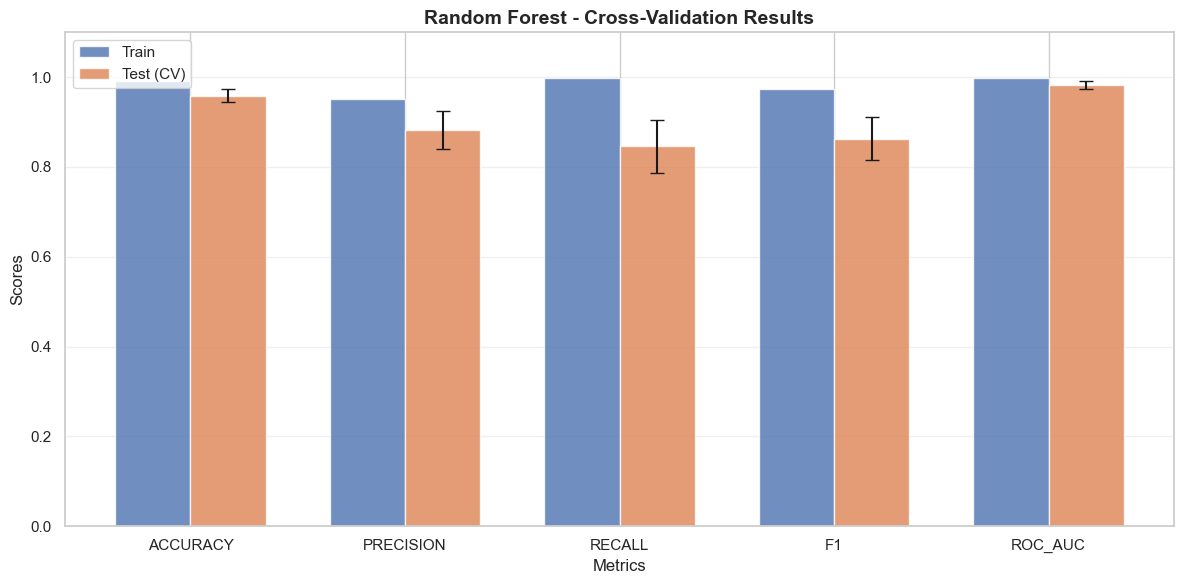

--
RANDOM FOREST - FINAL TEST SET EVALUATION
--
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       481
           1       0.89      0.87      0.88        89

    accuracy                           0.96       570
   macro avg       0.93      0.92      0.93       570
weighted avg       0.96      0.96      0.96       570



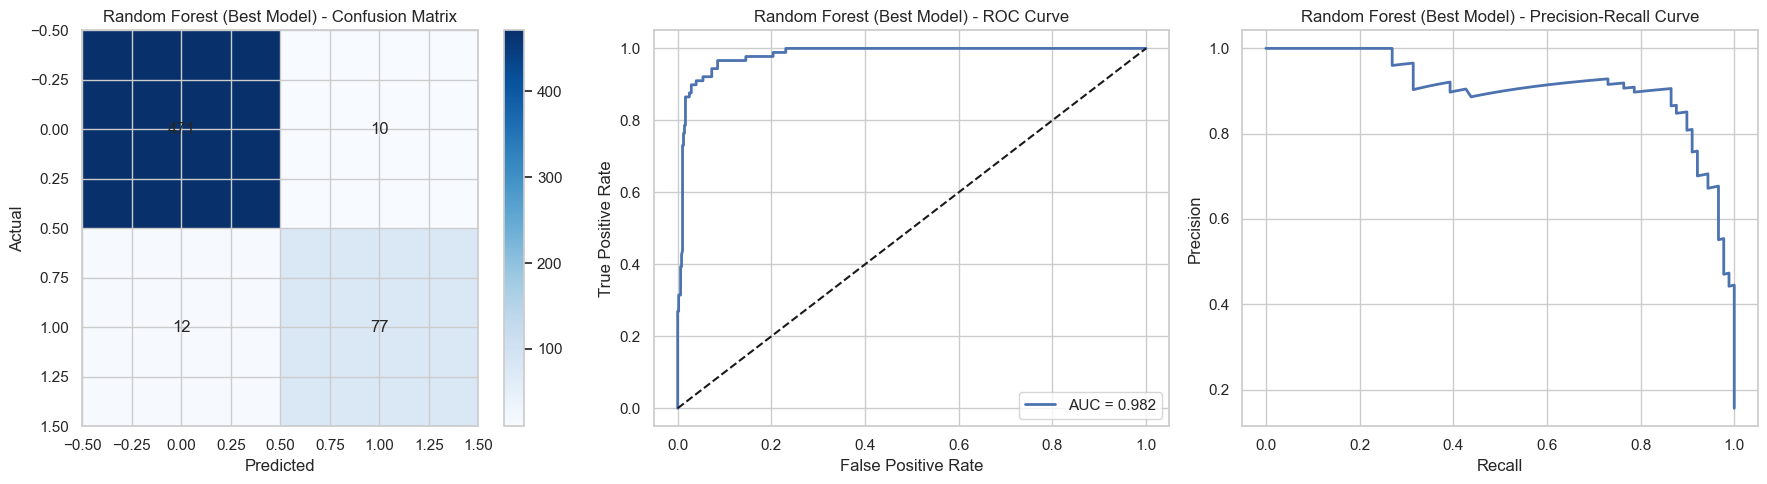

In [35]:
print("--")
print("MODEL 3: RANDOM FOREST")
print("--")

# Base model evaluation with CV
rf_base = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=4,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

#Evaluating base Random Forest with 5-Fold Stratified CV
cv_results_rf_base = cross_validate(
    rf_base, X_train, y_train, cv=skf,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    return_train_score=True, n_jobs=-1
)

print_cv_results(cv_results_rf_base, "Random Forest (Base)")

# Randomized Search for optimization
param_dist_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 12, 16],
    'min_samples_split': [2, 4, 8],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced']
}

rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)

random_rf = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist_rf,
    n_iter=20,
    scoring='f1',
    cv=skf,
    verbose=1,
    n_jobs=-1,
    random_state=42,
    return_train_score=True
)

#Performing Randomized Search with 5-Fold Stratified CV
random_rf.fit(X_train, y_train)

print(f"\nBest Parameters: {random_rf.best_params_}")
print(f"Best CV F1 Score: {random_rf.best_score_:.4f}")

best_rf = random_rf.best_estimator_
cv_results_rf = cross_validate(
    best_rf, X_train, y_train, cv=skf,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    return_train_score=True, n_jobs=-1
)

print_cv_results(cv_results_rf, "Random Forest (Best)")
plot_cv_comparison(cv_results_rf, "Random Forest")

best_rf.fit(X_train, y_train)
y_pred_rf = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

print("--")
print("RANDOM FOREST - FINAL TEST SET EVALUATION")
print("--")
print(classification_report(y_test, y_pred_rf))

plot_evaluation_curves("Random Forest (Best Model)", y_test, y_pred_rf, y_proba_rf)

results_summary.append({
    'Model': 'Random Forest',
    'CV F1': cv_results_rf['test_f1'].mean(),
    'CV ROC-AUC': cv_results_rf['test_roc_auc'].mean(),
    'Test F1': f1_score(y_test, y_pred_rf),
    'Test ROC-AUC': roc_auc_score(y_test, y_proba_rf),
    'Test Accuracy': accuracy_score(y_test, y_pred_rf)
})



# Hyper Parameters
-> n_estimators = 300 → number of trees in the forest

-> max_depth = 12 → prevents trees from growing too deep

-> min_samples_split = 4 → minimum samples needed to split a node

-> class_weight = 'balanced' → handles imbalanced dataset by giving equal importance to classes

-> n_jobs = -1 → uses all CPU cores for faster training

-> A RandomizedSearchCV is used to optimize Random Forest:

-> Tests a random subset of parameter combinations

-> Much faster than GridSearch


## XG BOOST

--
MODEL 4: XGBOOST
--
--
XGBoost (Base) - CROSS-VALIDATION RESULTS (5-Fold Stratified)
--
ACCURACY     - Train: 0.9961 (±0.0004) | CV Test: 0.9570 (±0.0089)
PRECISION    - Train: 0.9834 (±0.0045) | CV Test: 0.8901 (±0.0388)
RECALL       - Train: 0.9916 (±0.0036) | CV Test: 0.8291 (±0.0388)
F1           - Train: 0.9874 (±0.0013) | CV Test: 0.8578 (±0.0299)
ROC_AUC      - Train: 0.9999 (±0.0000) | CV Test: 0.9840 (±0.0058)
Fitting 5 folds for each of 243 candidates, totalling 1215 fits

Best Parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200, 'subsample': 1.0}
Best CV F1 Score: 0.8646
--
XGBoost (Best) - CROSS-VALIDATION RESULTS (5-Fold Stratified)
--
ACCURACY     - Train: 0.9904 (±0.0015) | CV Test: 0.9592 (±0.0107)
PRECISION    - Train: 0.9659 (±0.0027) | CV Test: 0.8975 (±0.0361)
RECALL       - Train: 0.9727 (±0.0081) | CV Test: 0.8346 (±0.0415)
F1           - Train: 0.9693 (±0.0049) | CV Test: 0.8646 (±0.0367)
ROC_AUC      - Train: 0.9992

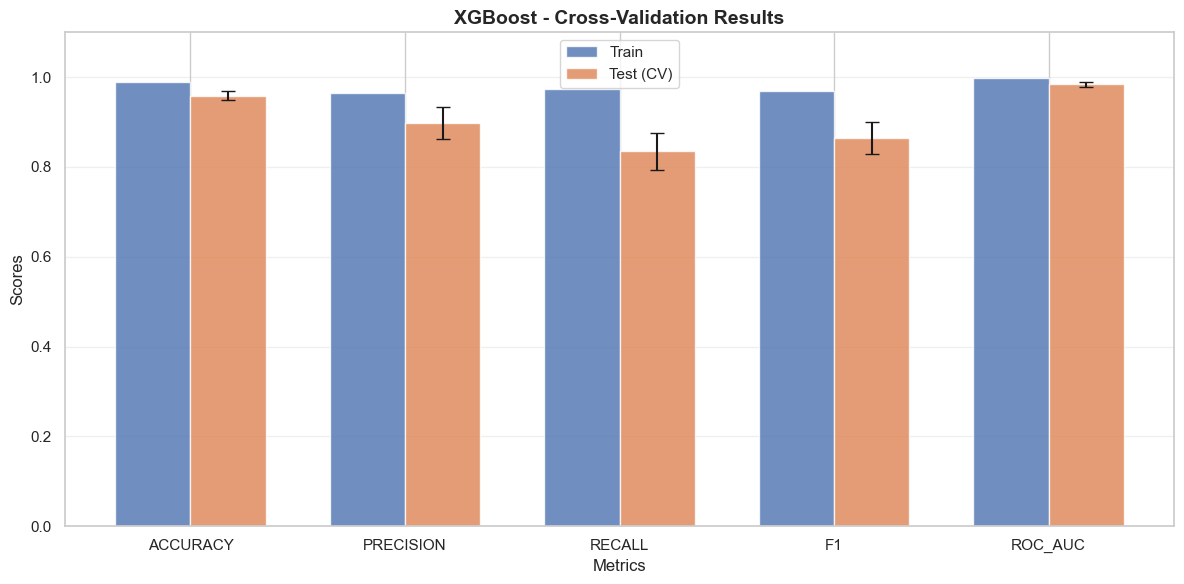

--
XGBOOST - FINAL TEST SET EVALUATION
--
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       481
           1       0.87      0.81      0.84        89

    accuracy                           0.95       570
   macro avg       0.92      0.89      0.90       570
weighted avg       0.95      0.95      0.95       570



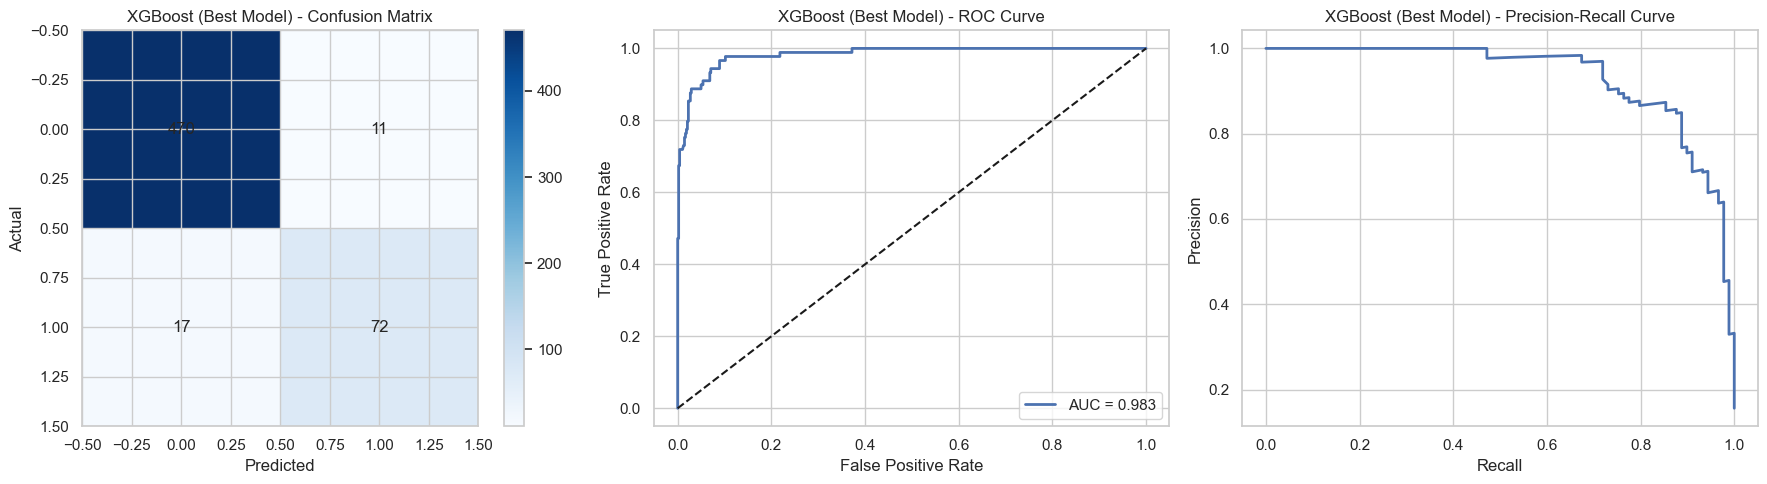

In [36]:
print("--")
print("MODEL 4: XGBOOST")
print("--")

# Base model evaluation with CV
xgb_base = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)

#Evaluating base XGBoost with 5-Fold Stratified CV
cv_results_xgb_base = cross_validate(
    xgb_base, X_train, y_train, cv=skf,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    return_train_score=True, n_jobs=-1
)

print_cv_results(cv_results_xgb_base, "XGBoost (Base)")

# Grid Search for optimization
param_grid_xgb = {
    'n_estimators': [200, 300, 400],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)

grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid_xgb,
    scoring='f1',
    cv=skf,
    verbose=1,
    n_jobs=-1,
    return_train_score=True
)

#Performing Grid Search with 5-Fold Stratified CV
grid_xgb.fit(X_train, y_train)

print(f"\nBest Parameters: {grid_xgb.best_params_}")
print(f"Best CV F1 Score: {grid_xgb.best_score_:.4f}")

best_xgb = grid_xgb.best_estimator_
cv_results_xgb = cross_validate(
    best_xgb, X_train, y_train, cv=skf,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
    return_train_score=True, n_jobs=-1
)

print_cv_results(cv_results_xgb, "XGBoost (Best)")
plot_cv_comparison(cv_results_xgb, "XGBoost")

best_xgb.fit(X_train, y_train)
y_pred_xgb = best_xgb.predict(X_test)
y_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("--")
print("XGBOOST - FINAL TEST SET EVALUATION")
print("--")
print(classification_report(y_test, y_pred_xgb))

plot_evaluation_curves("XGBoost (Best Model)", y_test, y_pred_xgb, y_proba_xgb)

results_summary.append({
    'Model': 'XGBoost',
    'CV F1': cv_results_xgb['test_f1'].mean(),
    'CV ROC-AUC': cv_results_xgb['test_roc_auc'].mean(),
    'Test F1': f1_score(y_test, y_pred_xgb),
    'Test ROC-AUC': roc_auc_score(y_test, y_proba_xgb),
    'Test Accuracy': accuracy_score(y_test, y_pred_xgb)
})

# Hyper parameters

-> n_estimators = 300 → 300 boosting trees

-> max_depth = 6 → controls tree complexity

-> learning_rate = 0.1 → how fast the model learns

-> subsample = 0.8 → trains each tree on 80% of samples (prevents overfitting)

-> colsample_bytree = 0.8 → uses 80% of features per tree

-> eval_metric = 'logloss' → standard metric for binary classification

->Finally, performance metrics are stored in results_summary to compare XGBoost with other models like Decision Tree, KNN, and Random Forest.

## Comparison of Models

--
FINAL MODEL COMPARISON
--

        Model  CV F1  CV ROC-AUC  Test F1  Test ROC-AUC  Test Accuracy
Decision Tree 0.8096      0.8978   0.8045        0.8910         0.9386
          KNN 0.8492      0.9595   0.8667        0.9542         0.9579
Random Forest 0.8633      0.9831   0.8750        0.9819         0.9614
Random Forest 0.8633      0.9831   0.8750        0.9819         0.9614
Decision Tree 0.8096      0.8978   0.8045        0.8910         0.9386
          KNN 0.8492      0.9595   0.8667        0.9542         0.9579
Random Forest 0.8633      0.9831   0.8750        0.9819         0.9614
      XGBoost 0.8646      0.9845   0.8372        0.9826         0.9509


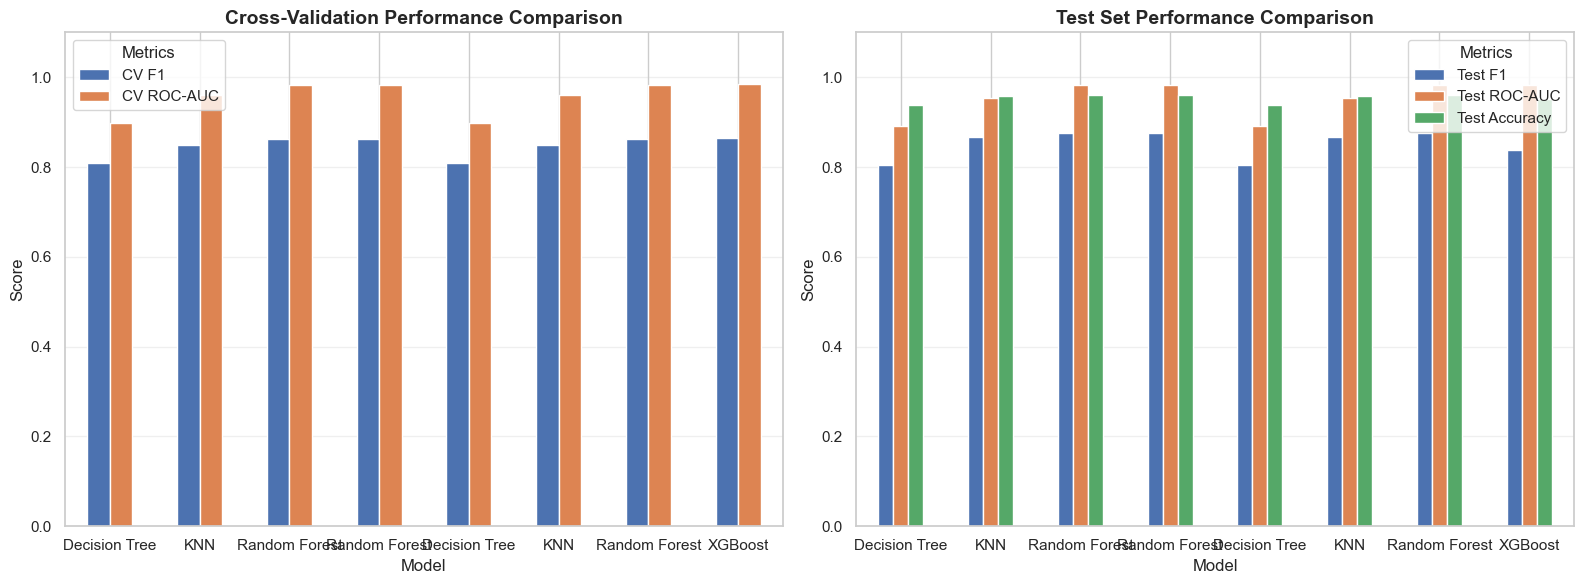

--
BEST MODEL: Random Forest
--
Test F1 Score: 0.8750
Test ROC-AUC: 0.9819
Test Accuracy: 0.9614
--
ALL MODELS TRAINING COMPLETE
--


In [37]:
print("--")
print("FINAL MODEL COMPARISON")
print("--")

comparison_df = pd.DataFrame(results_summary)
comparison_df = comparison_df.round(4)
print("\n" + comparison_df.to_string(index=False))

# Visualization of model comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CV Performance
metrics_cv = ['CV F1', 'CV ROC-AUC']
comparison_df.plot(x='Model', y=metrics_cv, kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Cross-Validation Performance Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_ylim([0, 1.1])
axes[0].legend(title='Metrics')
axes[0].grid(axis='y', alpha=0.3)

# Test Performance
metrics_test = ['Test F1', 'Test ROC-AUC', 'Test Accuracy']
comparison_df.plot(x='Model', y=metrics_test, kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Test Set Performance Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_ylim([0, 1.1])
axes[1].legend(title='Metrics')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Identify best model
best_model_idx = comparison_df['Test F1'].idxmax()
best_model_name = comparison_df.loc[best_model_idx, 'Model']

print("--")
print(f"BEST MODEL: {best_model_name}")
print("--")
print(f"Test F1 Score: {comparison_df.loc[best_model_idx, 'Test F1']:.4f}")
print(f"Test ROC-AUC: {comparison_df.loc[best_model_idx, 'Test ROC-AUC']:.4f}")
print(f"Test Accuracy: {comparison_df.loc[best_model_idx, 'Test Accuracy']:.4f}")

print("--")
print("ALL MODELS TRAINING COMPLETE")
print("--")

A. Cross-Validation Graph

Uses 'CV F1' and 'CV ROC-AUC' values.

Makes a bar chart comparing all models side-by-side.

B. Test Performance Graph

Uses 'Test F1', 'Test ROC-AUC', 'Test Accuracy'.

-> idxmax() finds the model with the highest Test F1 score.

F1 is chosen because:

It balances precision + recall


The code then prints:

Best model name

Its Test F1

Test ROC-AUC

Test accuracy

This gives a clear summary of the winning model.

## Explainable AI

--
MODEL EXPLAINABILITY ANALYSIS
--
--
1. DECISION TREE EXPLAINABILITY (TreeInterpreter)
--
Decision Tree Accuracy: 93.86%


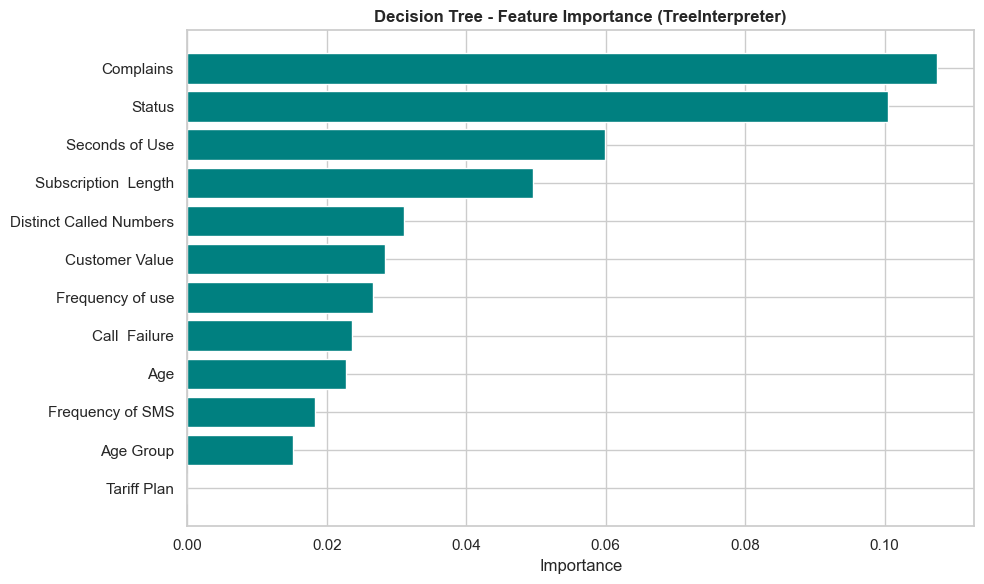

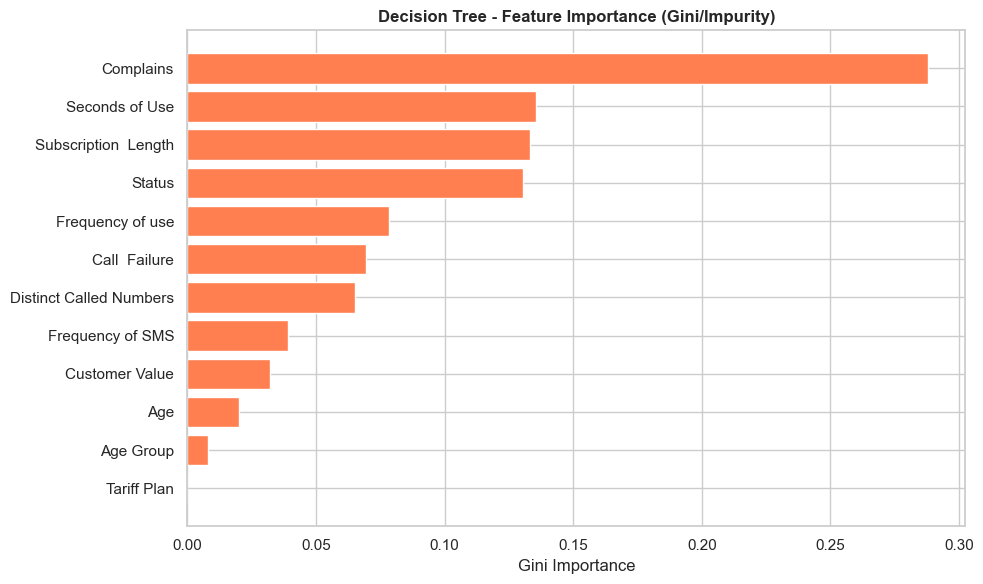

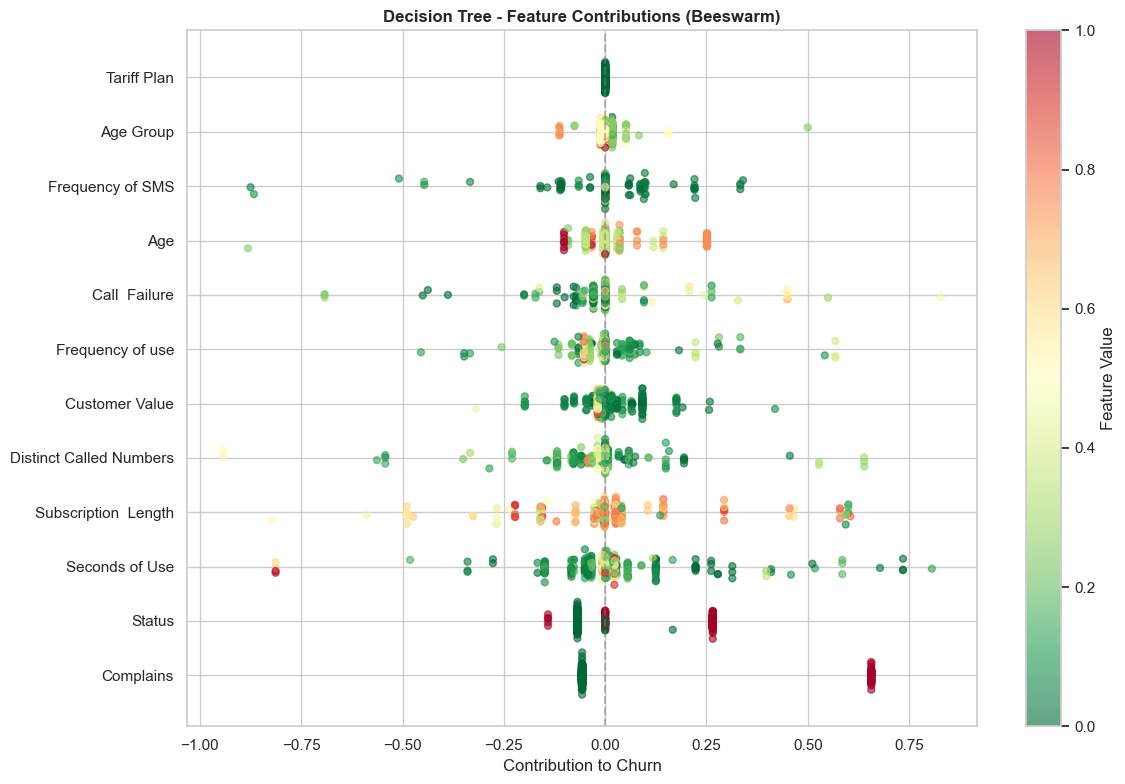

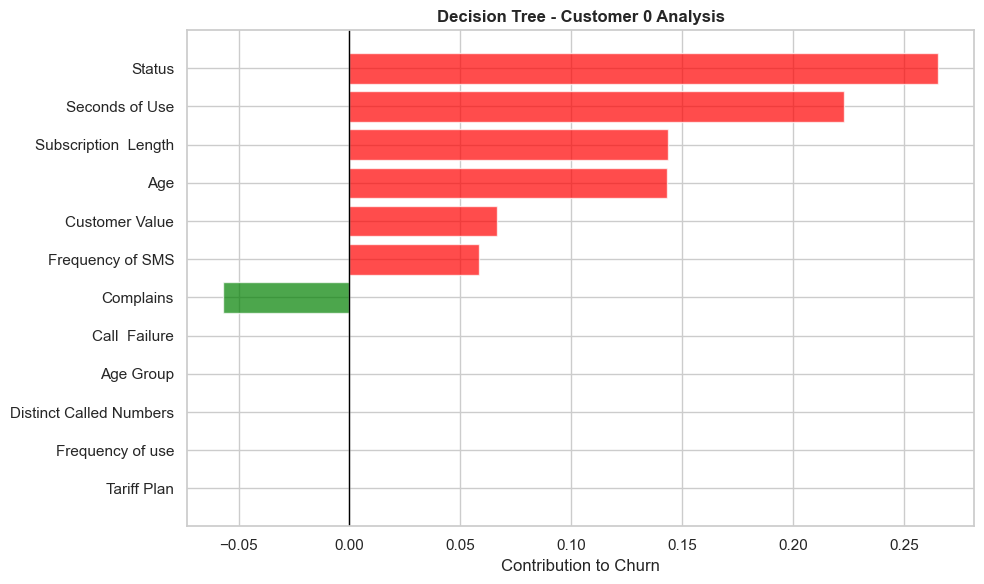

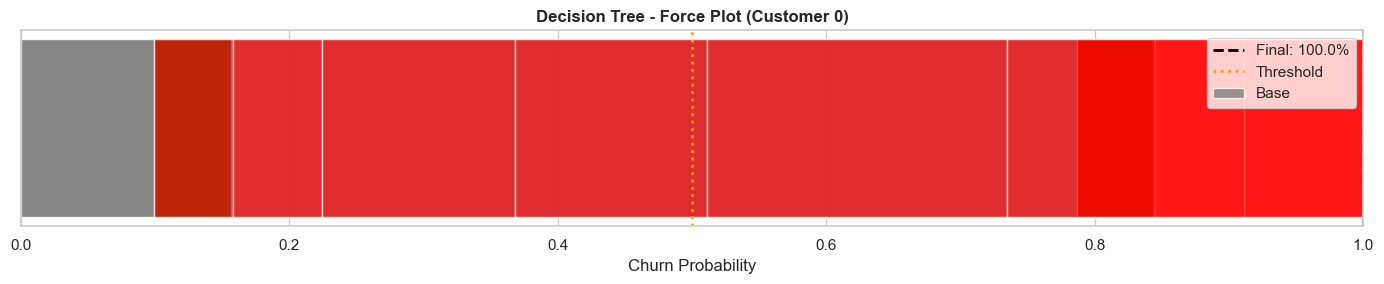

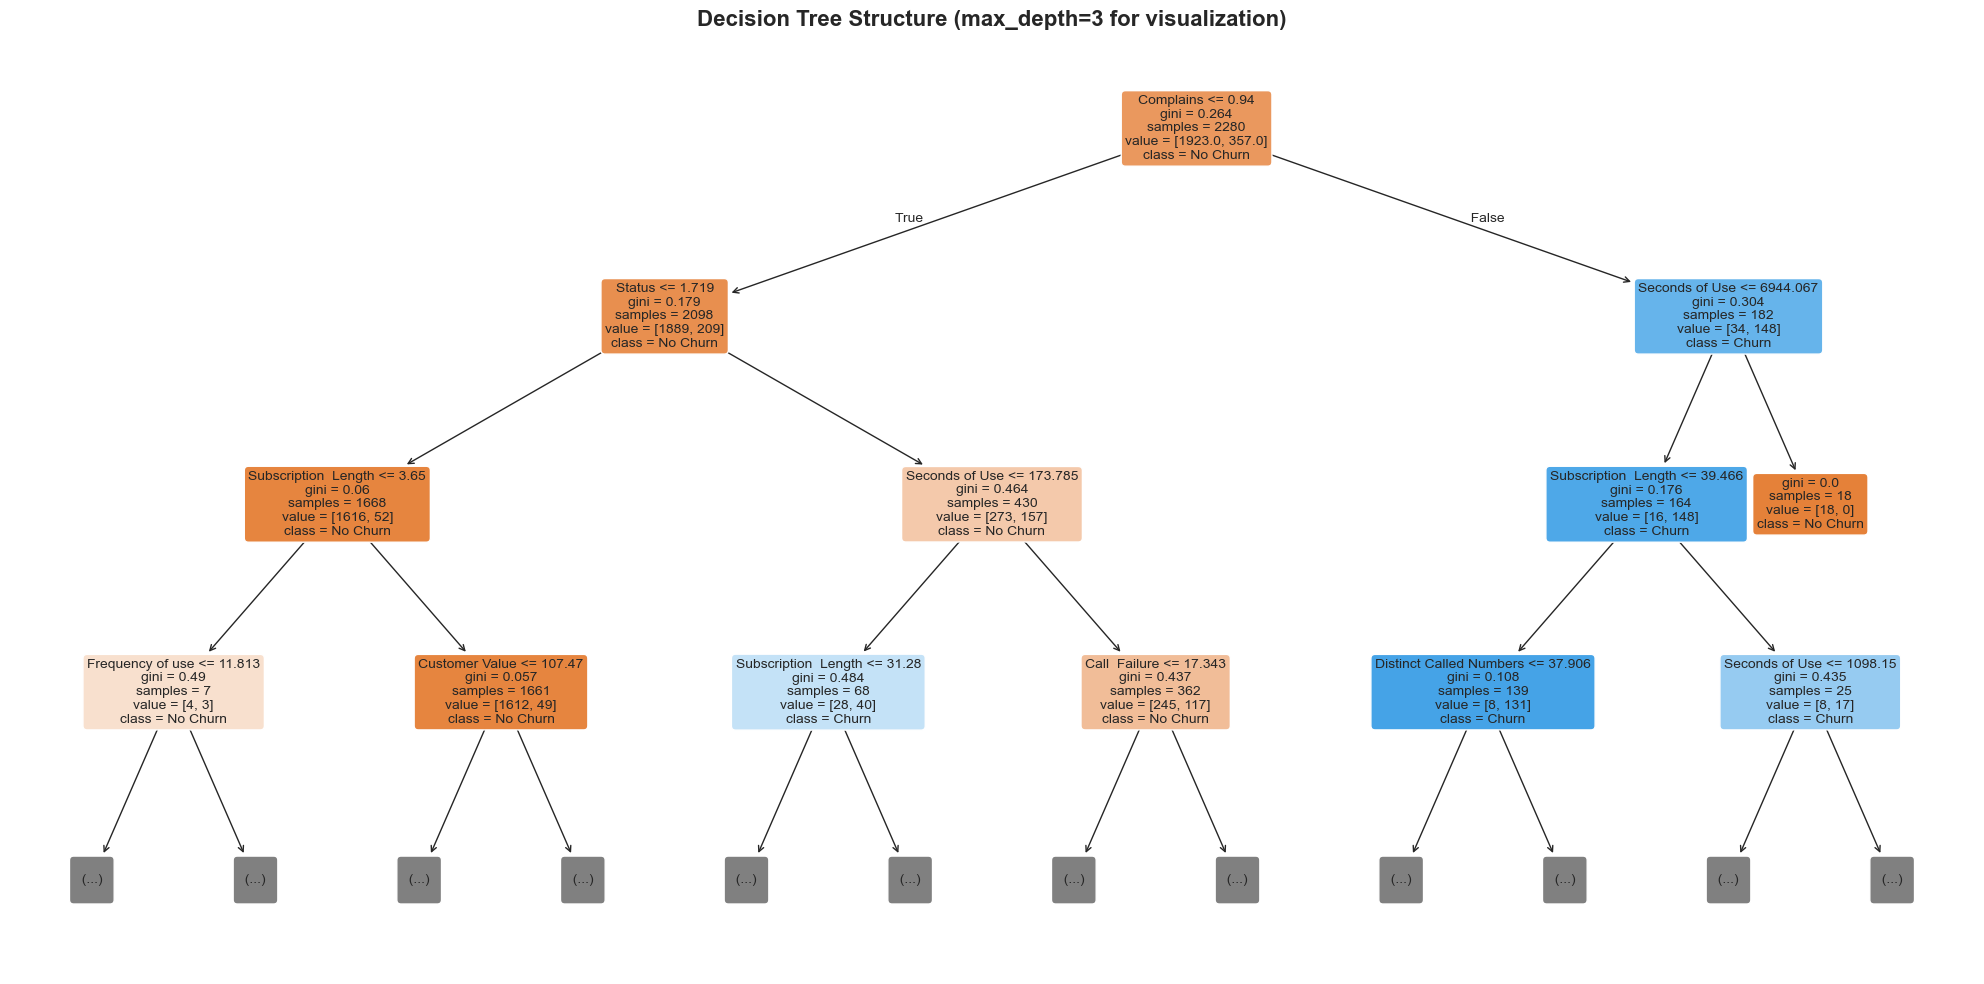


Decision Tree - Top Features (TreeInterpreter):
                Feature  Importance
              Complains    0.107457
                 Status    0.100509
         Seconds of Use    0.059883
   Subscription  Length    0.049511
Distinct Called Numbers    0.031025
         Customer Value    0.028281
       Frequency of use    0.026607
          Call  Failure    0.023673
                    Age    0.022690
       Frequency of SMS    0.018311

Customer 0 - Churn Probability: 100.0%
             Feature  Contribution
              Status      0.265498
      Seconds of Use      0.223119
Subscription  Length      0.143472
                 Age      0.143293
      Customer Value      0.066667
--
2. RANDOM FOREST EXPLAINABILITY (TreeInterpreter)
--
Random Forest Accuracy: 96.14%


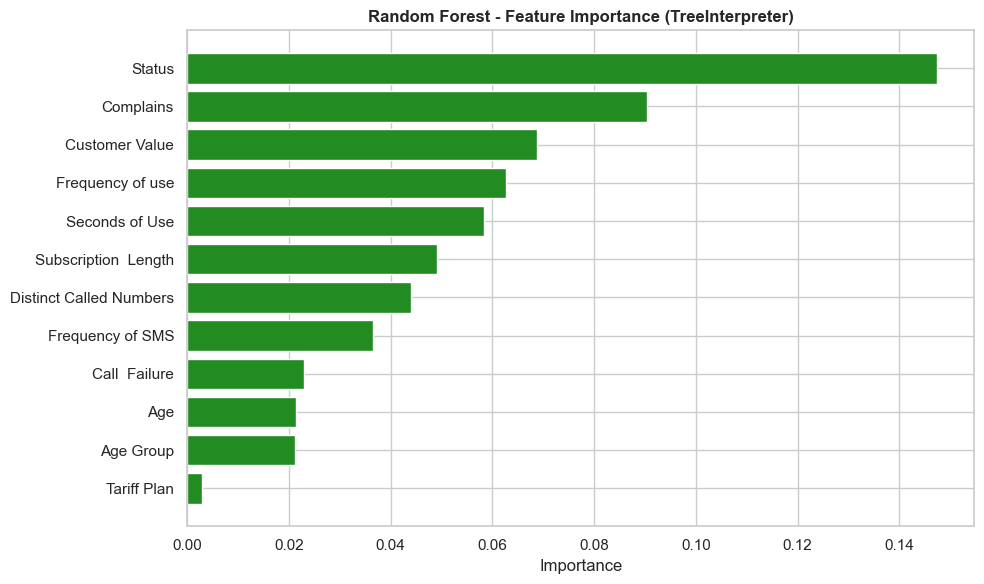

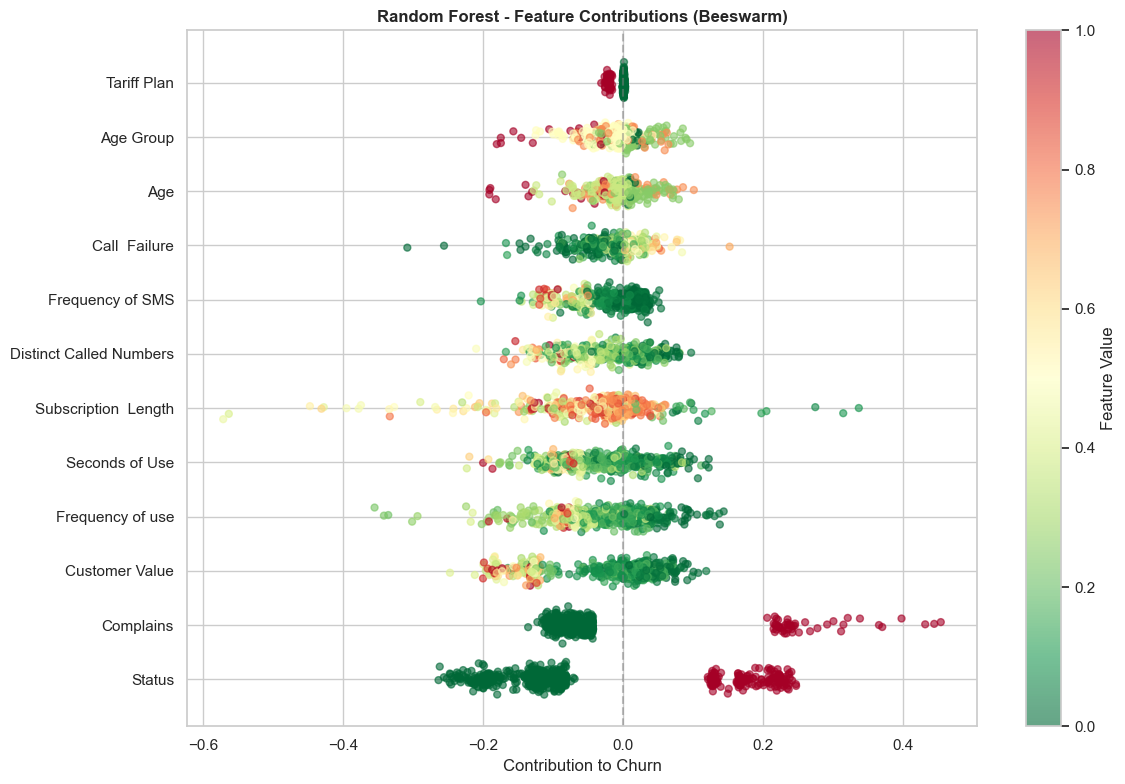

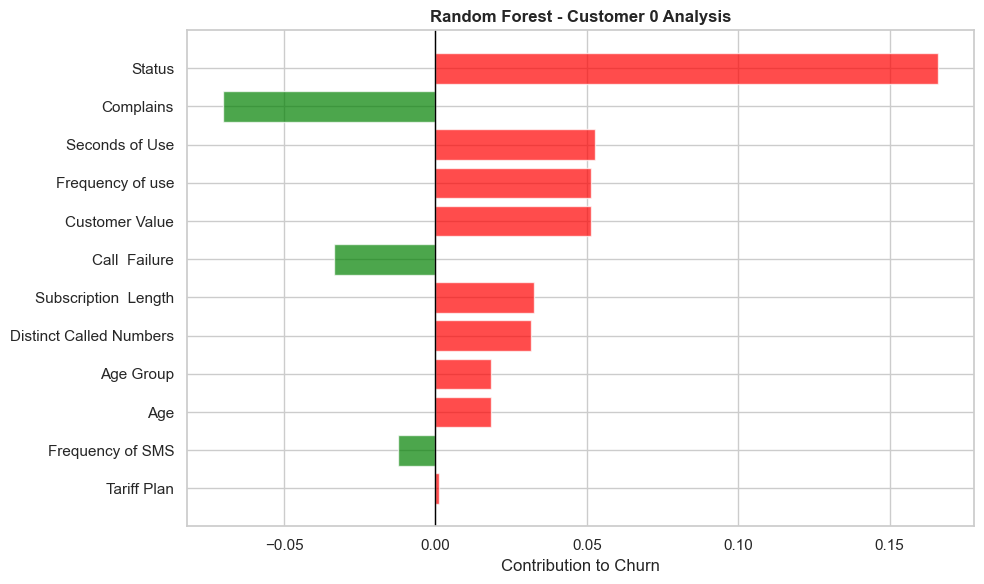

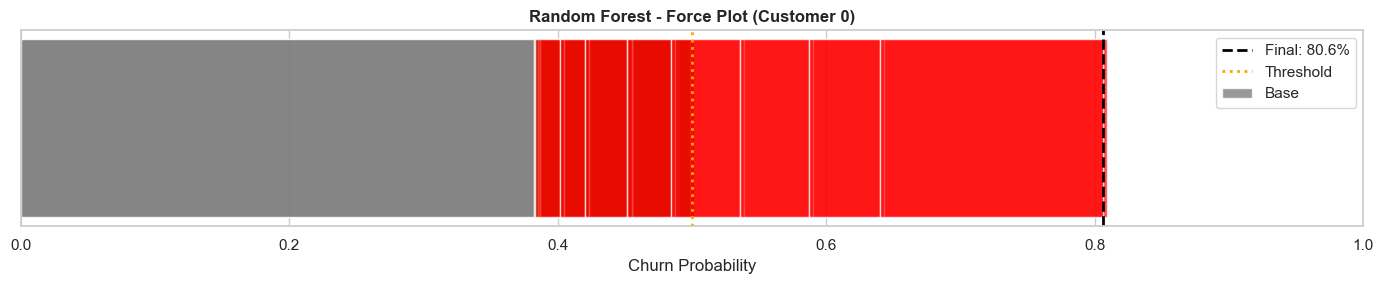


Random Forest - Top Features:
                Feature  Importance
                 Status    0.147342
              Complains    0.090393
         Customer Value    0.068672
       Frequency of use    0.062757
         Seconds of Use    0.058438
   Subscription  Length    0.049160
Distinct Called Numbers    0.043994
       Frequency of SMS    0.036553
          Call  Failure    0.023021
                    Age    0.021423

Customer 0 - Churn Probability: 80.6%
         Feature  Contribution
          Status      0.166020
       Complains     -0.070120
  Seconds of Use      0.052639
Frequency of use      0.051508
  Customer Value      0.051402
--
3. XGBOOST EXPLAINABILITY (SHAP)
--
XGBoost Accuracy: 95.09%

Calculating SHAP values for XGBoost...


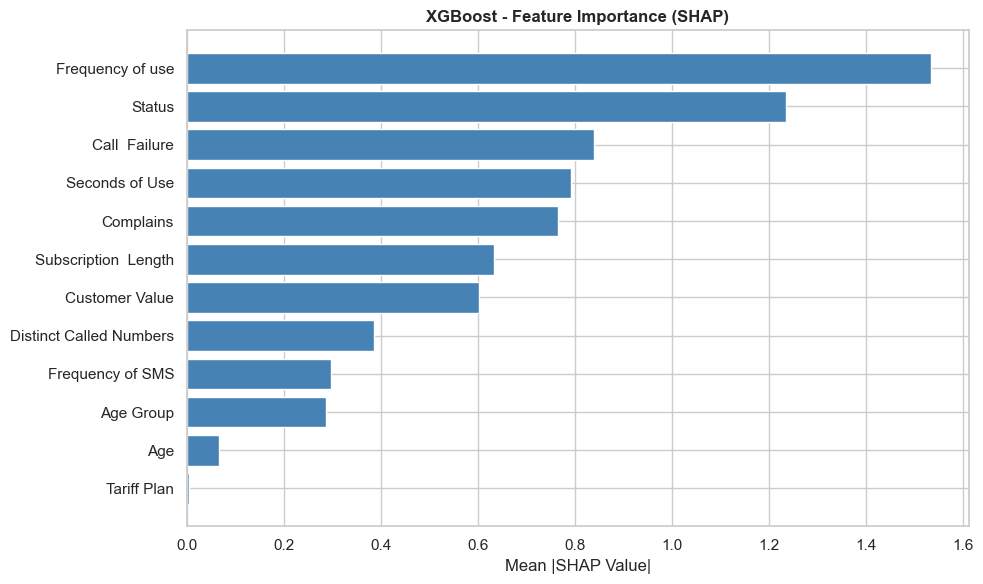

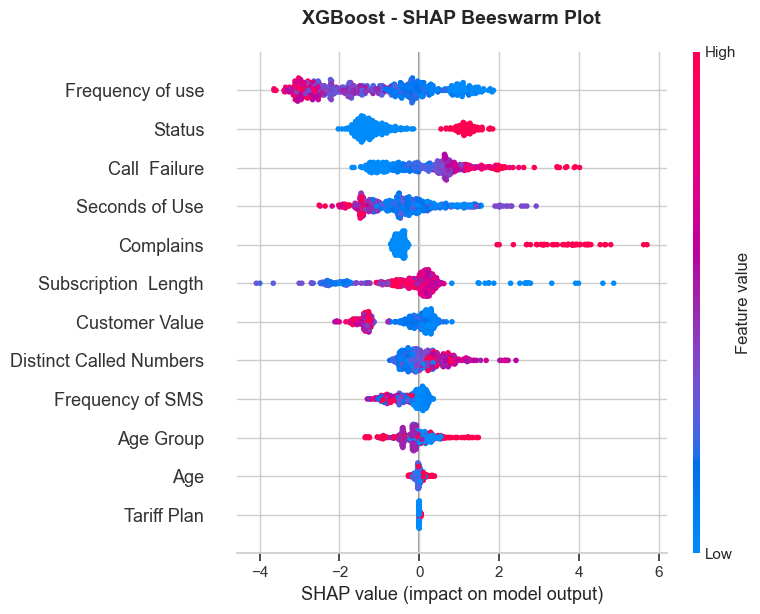

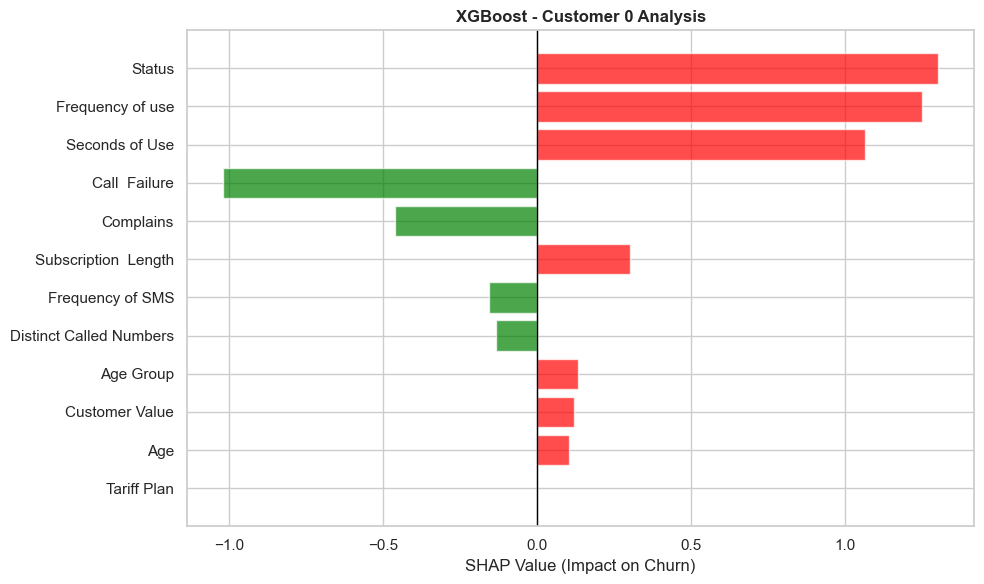

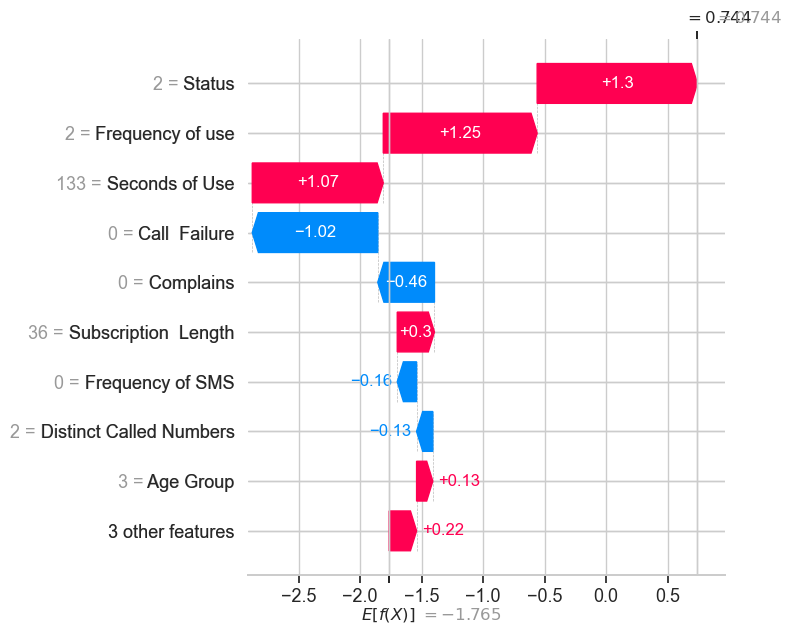

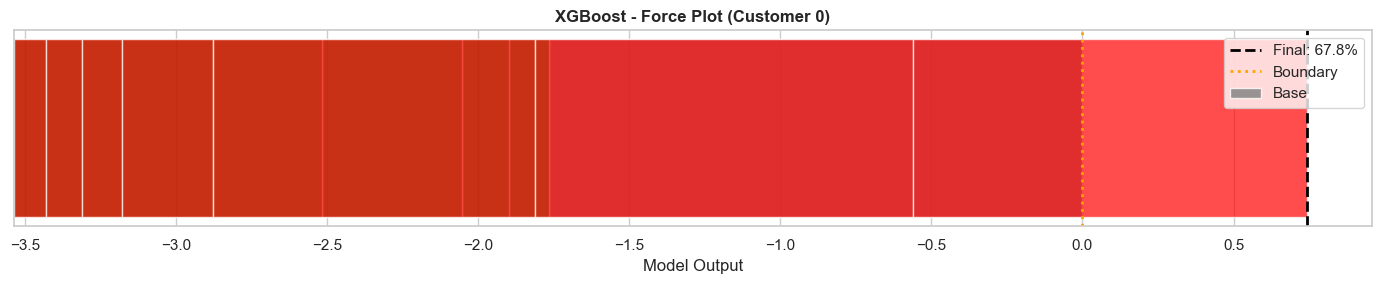

<Figure size 1000x600 with 0 Axes>

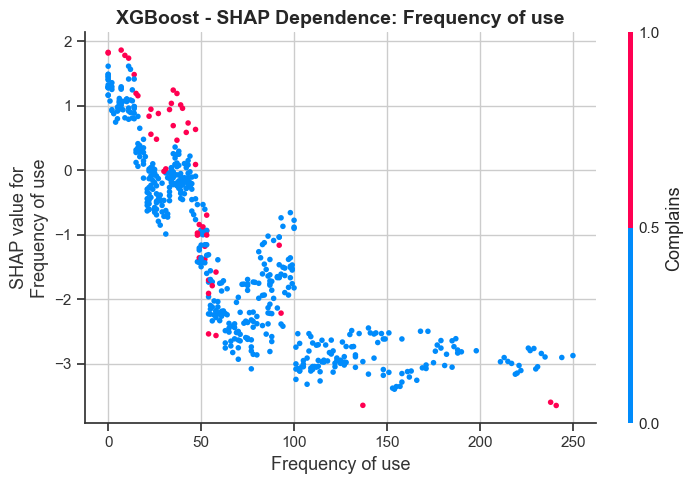


XGBoost - Top Features:
                Feature  Importance
       Frequency of use    1.533980
                 Status    1.234100
          Call  Failure    0.837748
         Seconds of Use    0.791724
              Complains    0.763527
   Subscription  Length    0.632200
         Customer Value    0.602125
Distinct Called Numbers    0.385085
       Frequency of SMS    0.295912
              Age Group    0.285098

Customer 0 - Churn Probability: 67.8%
         Feature  SHAP_Value
          Status    1.304055
Frequency of use    1.251593
  Seconds of Use    1.065597
   Call  Failure   -1.020785
       Complains   -0.461138
--
4. KNN EXPLAINABILITY (SHAP KernelExplainer)
--
KNN Accuracy: 95.79%
Computing SHAP values for 50 samples...


100%|██████████| 50/50 [04:28<00:00,  5.37s/it]


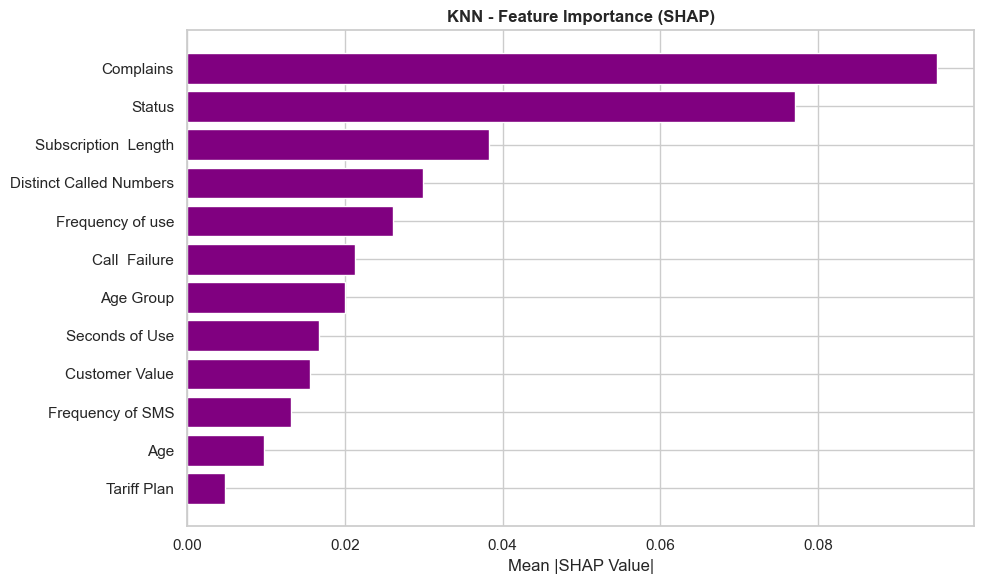

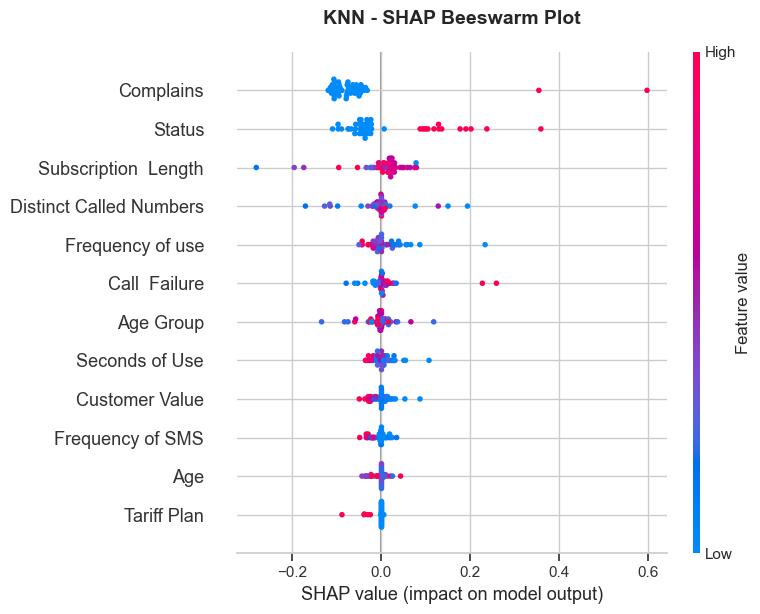

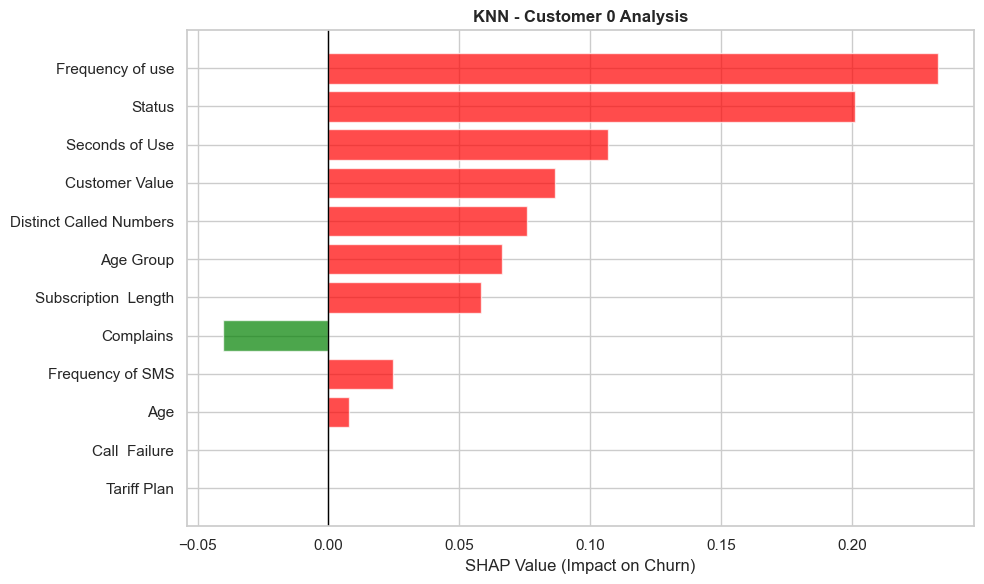

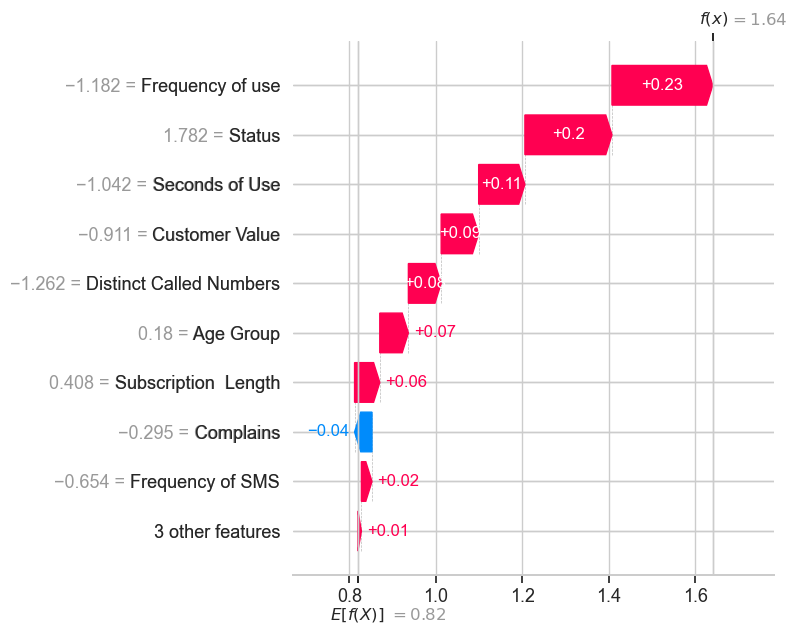

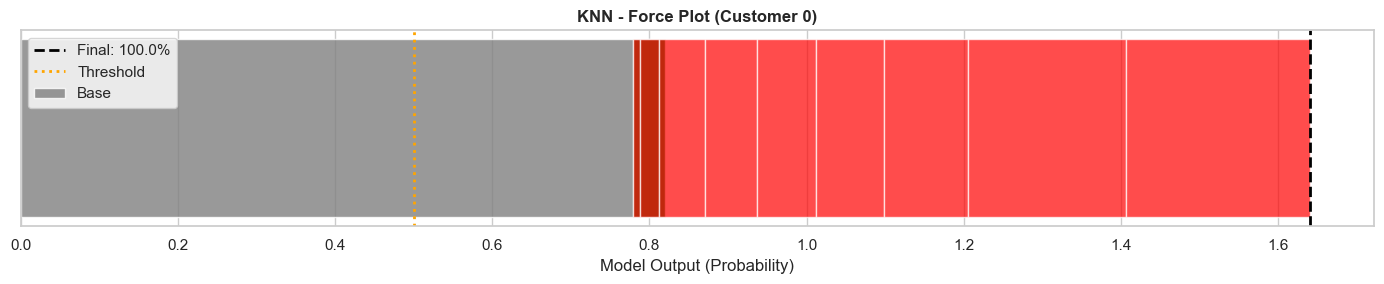

<Figure size 1000x600 with 0 Axes>

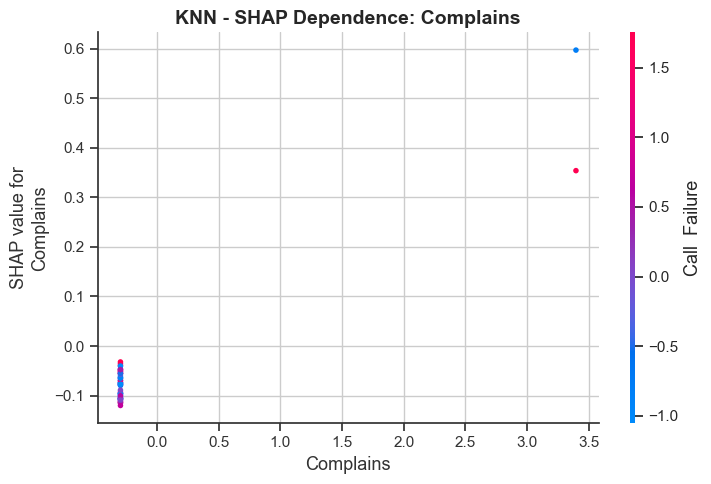


KNN - Top Features:
                Feature  Importance
              Complains    0.095025
                 Status    0.077110
   Subscription  Length    0.038275
Distinct Called Numbers    0.029850
       Frequency of use    0.026035
          Call  Failure    0.021315
              Age Group    0.019982
         Seconds of Use    0.016653
         Customer Value    0.015613
       Frequency of SMS    0.013131

Customer 0 - Churn Probability: 100.0%
                Feature  SHAP_Value
       Frequency of use    0.232917
                 Status    0.201226
         Seconds of Use    0.106838
         Customer Value    0.086670
Distinct Called Numbers    0.075793

Nearest 5 Neighbors:
  Neighbor 1: Distance=0.191, Actual=Churned
  Neighbor 2: Distance=0.304, Actual=Churned
  Neighbor 3: Distance=0.304, Actual=Churned
  Neighbor 4: Distance=0.397, Actual=Retained
  Neighbor 5: Distance=0.406, Actual=Churned

Note: KNN analysis performed on 50 samples for computational efficiency
--
EXP

In [38]:
from treeinterpreter import treeinterpreter as ti

import shap
import numpy as np

sns.set(style="whitegrid")

print("--")
print("MODEL EXPLAINABILITY ANALYSIS")
print("--")

# Get feature names
features = X_train.columns.tolist()

# 1. DECISION TREE - TREEINTERPRETER

print("--")
print("1. DECISION TREE EXPLAINABILITY (TreeInterpreter)")
print("--")

predictions_dt, bias_dt, contributions_dt = ti.predict(best_dt, X_test)
churn_contributions_dt = contributions_dt[:, :, 1]
churn_predictions_dt = predictions_dt[:, 1]
base_prob_dt = bias_dt[1]

print(f"Decision Tree Accuracy: {accuracy_score(y_test, best_dt.predict(X_test)):.2%}")

# Feature importance (TreeInterpreter)
mean_importance_dt = np.abs(churn_contributions_dt).mean(axis=0)
importance_df_dt = pd.DataFrame({'Feature': features, 'Importance': mean_importance_dt})
importance_df_dt = importance_df_dt.sort_values('Importance', ascending=False)

# Plot 1: TreeInterpreter Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df_dt['Feature'], importance_df_dt['Importance'], color='teal')
plt.xlabel('Importance')
plt.title('Decision Tree - Feature Importance (TreeInterpreter)', fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 2: Gini Feature Importance
gini_importance_dt = pd.DataFrame({'Feature': features, 'Gini': best_dt.feature_importances_})
gini_importance_dt = gini_importance_dt.sort_values('Gini', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(gini_importance_dt['Feature'], gini_importance_dt['Gini'], color='coral')
plt.xlabel('Gini Importance')
plt.title('Decision Tree - Feature Importance (Gini/Impurity)', fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 3: Beeswarm plot
sorted_features_dt = importance_df_dt['Feature'].tolist()
sorted_indices_dt = [features.index(f) for f in sorted_features_dt]

plt.figure(figsize=(12, 8))
for plot_idx, feature_idx in enumerate(sorted_indices_dt):
    contribs = churn_contributions_dt[:, feature_idx]
    feature_values = X_test.iloc[:, feature_idx].values
    normalized_values = (feature_values - feature_values.min()) / (feature_values.max() - feature_values.min() + 1e-10)

    plt.scatter(contribs, np.random.normal(plot_idx, 0.1, size=len(contribs)),
                c=normalized_values, cmap='RdYlGn_r', alpha=0.6, s=25)

plt.yticks(range(len(sorted_features_dt)), sorted_features_dt)
plt.xlabel('Contribution to Churn')
plt.title('Decision Tree - Feature Contributions (Beeswarm)', fontweight='bold')
plt.colorbar(label='Feature Value')
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Analyze specific customer
customer_id = 0
customer_contrib_dt = pd.DataFrame({
    'Feature': features,
    'Contribution': churn_contributions_dt[customer_id]
}).sort_values('Contribution', key=abs, ascending=False)

# Plot 4: Customer-specific analysis
plt.figure(figsize=(10, 6))
colors = ['red' if c > 0 else 'green' for c in customer_contrib_dt['Contribution']]
plt.barh(customer_contrib_dt['Feature'], customer_contrib_dt['Contribution'], color=colors, alpha=0.7)
plt.xlabel('Contribution to Churn')
plt.title(f'Decision Tree - Customer {customer_id} Analysis', fontweight='bold')
plt.axvline(x=0, color='black', linewidth=1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 5: Force plot
churn_prob_dt = churn_predictions_dt[customer_id]
positive_contrib_dt = customer_contrib_dt[customer_contrib_dt['Contribution'] > 0].sort_values('Contribution')
negative_contrib_dt = customer_contrib_dt[customer_contrib_dt['Contribution'] < 0].sort_values('Contribution', ascending=False)

fig, ax = plt.subplots(figsize=(14, 3))
current_pos = base_prob_dt

ax.barh(0, base_prob_dt, left=0, height=0.5, color='gray', alpha=0.8, label='Base')
for _, row in negative_contrib_dt.iterrows():
    ax.barh(0, row['Contribution'], left=current_pos, height=0.5, color='green', alpha=0.7)
    current_pos += row['Contribution']
for _, row in positive_contrib_dt.iterrows():
    ax.barh(0, row['Contribution'], left=current_pos, height=0.5, color='red', alpha=0.7)
    current_pos += row['Contribution']

ax.axvline(x=churn_prob_dt, color='black', linestyle='--', linewidth=2, label=f'Final: {churn_prob_dt:.1%}')
ax.axvline(x=0.5, color='orange', linestyle=':', linewidth=2, label='Threshold')
ax.set_yticks([])
ax.set_xlabel('Churn Probability')
ax.set_xlim(0, 1)
ax.set_title(f'Decision Tree - Force Plot (Customer {customer_id})', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# Plot 6: Tree structure visualization
plt.figure(figsize=(20, 10))
plot_tree(best_dt, feature_names=features, class_names=['No Churn', 'Churn'],
          filled=True, rounded=True, fontsize=10, max_depth=3)
plt.title('Decision Tree Structure (max_depth=3 for visualization)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nDecision Tree - Top Features (TreeInterpreter):")
print(importance_df_dt.head(10).to_string(index=False))
print(f"\nCustomer {customer_id} - Churn Probability: {churn_prob_dt:.1%}")
print(customer_contrib_dt.head(5).to_string(index=False))


# 2. RANDOM FOREST - TREEINTERPRETER

print("--")
print("2. RANDOM FOREST EXPLAINABILITY (TreeInterpreter)")
print("--")

predictions_rf, bias_rf, contributions_rf = ti.predict(best_rf, X_test)
churn_contributions_rf = contributions_rf[:, :, 1]

print(f"Random Forest Accuracy: {accuracy_score(y_test, best_rf.predict(X_test)):.2%}")

# Feature importance
mean_importance_rf = np.abs(churn_contributions_rf).mean(axis=0)
importance_df_rf = pd.DataFrame({'Feature': features, 'Importance': mean_importance_rf})
importance_df_rf = importance_df_rf.sort_values('Importance', ascending=False)

# Plot 1: Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df_rf['Feature'], importance_df_rf['Importance'], color='forestgreen')
plt.xlabel('Importance')
plt.title('Random Forest - Feature Importance (TreeInterpreter)', fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 2: Beeswarm plot
sorted_features_rf = importance_df_rf['Feature'].tolist()
sorted_indices_rf = [features.index(f) for f in sorted_features_rf]

plt.figure(figsize=(12, 8))
for plot_idx, feature_idx in enumerate(sorted_indices_rf):
    contribs = churn_contributions_rf[:, feature_idx]
    feature_values = X_test.iloc[:, feature_idx].values
    normalized_values = (feature_values - feature_values.min()) / (feature_values.max() - feature_values.min() + 1e-10)

    plt.scatter(contribs, np.random.normal(plot_idx, 0.1, size=len(contribs)),
                c=normalized_values, cmap='RdYlGn_r', alpha=0.6, s=25)

plt.yticks(range(len(sorted_features_rf)), sorted_features_rf)
plt.xlabel('Contribution to Churn')
plt.title('Random Forest - Feature Contributions (Beeswarm)', fontweight='bold')
plt.colorbar(label='Feature Value')
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Customer analysis
customer_contrib_rf = pd.DataFrame({
    'Feature': features,
    'Contribution': churn_contributions_rf[customer_id]
}).sort_values('Contribution', key=abs, ascending=False)

# Plot 3: Customer-specific analysis
plt.figure(figsize=(10, 6))
colors = ['red' if c > 0 else 'green' for c in customer_contrib_rf['Contribution']]
plt.barh(customer_contrib_rf['Feature'], customer_contrib_rf['Contribution'], color=colors, alpha=0.7)
plt.xlabel('Contribution to Churn')
plt.title(f'Random Forest - Customer {customer_id} Analysis', fontweight='bold')
plt.axvline(x=0, color='black', linewidth=1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 4: Force plot
churn_prob_rf = predictions_rf[customer_id, 1]
base_prob_rf = bias_rf[1]
positive_contrib_rf = customer_contrib_rf[customer_contrib_rf['Contribution'] > 0].sort_values('Contribution')
negative_contrib_rf = customer_contrib_rf[customer_contrib_rf['Contribution'] < 0].sort_values('Contribution', ascending=False)

fig, ax = plt.subplots(figsize=(14, 3))
current_pos = base_prob_rf

ax.barh(0, base_prob_rf, left=0, height=0.5, color='gray', alpha=0.8, label='Base')
for _, row in negative_contrib_rf.iterrows():
    ax.barh(0, row['Contribution'], left=current_pos, height=0.5, color='green', alpha=0.7)
    current_pos += row['Contribution']
for _, row in positive_contrib_rf.iterrows():
    ax.barh(0, row['Contribution'], left=current_pos, height=0.5, color='red', alpha=0.7)
    current_pos += row['Contribution']

ax.axvline(x=churn_prob_rf, color='black', linestyle='--', linewidth=2, label=f'Final: {churn_prob_rf:.1%}')
ax.axvline(x=0.5, color='orange', linestyle=':', linewidth=2, label='Threshold')
ax.set_yticks([])
ax.set_xlabel('Churn Probability')
ax.set_xlim(0, 1)
ax.set_title(f'Random Forest - Force Plot (Customer {customer_id})', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print("\nRandom Forest - Top Features:")
print(importance_df_rf.head(10).to_string(index=False))
print(f"\nCustomer {customer_id} - Churn Probability: {churn_prob_rf:.1%}")
print(customer_contrib_rf.head(5).to_string(index=False))


# 3. XGBOOST - SHAP
print("--")
print("3. XGBOOST EXPLAINABILITY (SHAP)")
print("--")

print(f"XGBoost Accuracy: {accuracy_score(y_test, best_xgb.predict(X_test)):.2%}")

# Calculate SHAP values
print("\nCalculating SHAP values for XGBoost...")
explainer_xgb = shap.TreeExplainer(best_xgb)
shap_values_xgb = explainer_xgb(X_test)
shap_values_churn_xgb = shap_values_xgb.values[:, :, 1] if len(shap_values_xgb.values.shape) == 3 else shap_values_xgb.values
base_value_xgb = explainer_xgb.expected_value[1] if isinstance(explainer_xgb.expected_value, np.ndarray) else explainer_xgb.expected_value

# Feature importance
mean_importance_xgb = np.abs(shap_values_churn_xgb).mean(axis=0)
importance_df_xgb = pd.DataFrame({'Feature': features, 'Importance': mean_importance_xgb})
importance_df_xgb = importance_df_xgb.sort_values('Importance', ascending=False)

# Plot 1: Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df_xgb['Feature'], importance_df_xgb['Importance'], color='steelblue')
plt.xlabel('Mean |SHAP Value|')
plt.title('XGBoost - Feature Importance (SHAP)', fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 2: SHAP Beeswarm Plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_churn_xgb, X_test, feature_names=features, show=False)
plt.title('XGBoost - SHAP Beeswarm Plot', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Customer analysis
churn_prob_xgb = best_xgb.predict_proba(X_test)[:, 1][customer_id]
customer_contrib_xgb = pd.DataFrame({
    'Feature': features,
    'SHAP_Value': shap_values_churn_xgb[customer_id]
}).sort_values('SHAP_Value', key=abs, ascending=False)

# Plot 3: Customer-specific analysis
plt.figure(figsize=(10, 6))
colors = ['red' if s > 0 else 'green' for s in customer_contrib_xgb['SHAP_Value']]
plt.barh(customer_contrib_xgb['Feature'], customer_contrib_xgb['SHAP_Value'], color=colors, alpha=0.7)
plt.xlabel('SHAP Value (Impact on Churn)')
plt.title(f'XGBoost - Customer {customer_id} Analysis', fontweight='bold')
plt.axvline(x=0, color='black', linewidth=1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 4: SHAP Waterfall Plot
plt.figure(figsize=(12, 7))
shap.waterfall_plot(shap.Explanation(
    values=shap_values_churn_xgb[customer_id],
    base_values=base_value_xgb,
    data=X_test.iloc[customer_id].values,
    feature_names=features
), show=False)
plt.tight_layout()
plt.show()

# Plot 5: Force Plot
positive_shap_xgb = customer_contrib_xgb[customer_contrib_xgb['SHAP_Value'] > 0].sort_values('SHAP_Value')
negative_shap_xgb = customer_contrib_xgb[customer_contrib_xgb['SHAP_Value'] < 0].sort_values('SHAP_Value', ascending=False)

fig, ax = plt.subplots(figsize=(14, 3))
current_pos = base_value_xgb

ax.barh(0, base_value_xgb, left=0, height=0.5, color='gray', alpha=0.8, label='Base')
for _, row in negative_shap_xgb.iterrows():
    ax.barh(0, row['SHAP_Value'], left=current_pos, height=0.5, color='green', alpha=0.7)
    current_pos += row['SHAP_Value']
for _, row in positive_shap_xgb.iterrows():
    ax.barh(0, row['SHAP_Value'], left=current_pos, height=0.5, color='red', alpha=0.7)
    current_pos += row['SHAP_Value']

final_value_xgb = base_value_xgb + shap_values_churn_xgb[customer_id].sum()
ax.axvline(x=final_value_xgb, color='black', linestyle='--', linewidth=2, label=f'Final: {churn_prob_xgb:.1%}')
ax.axvline(x=0, color='orange', linestyle=':', linewidth=2, label='Boundary')
ax.set_yticks([])
ax.set_xlabel('Model Output')
ax.set_title(f'XGBoost - Force Plot (Customer {customer_id})', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# Plot 6: Dependence Plot for top feature
top_feature_xgb = importance_df_xgb['Feature'].iloc[0]
top_feature_idx_xgb = features.index(top_feature_xgb)

plt.figure(figsize=(10, 6))
shap.dependence_plot(top_feature_idx_xgb, shap_values_churn_xgb, X_test,
                     feature_names=features, show=False)
plt.title(f'XGBoost - SHAP Dependence: {top_feature_xgb}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nXGBoost - Top Features:")
print(importance_df_xgb.head(10).to_string(index=False))
print(f"\nCustomer {customer_id} - Churn Probability: {churn_prob_xgb:.1%}")
print(customer_contrib_xgb.head(5).to_string(index=False))


# 4. KNN - SHAP
print("--")
print("4. KNN EXPLAINABILITY (SHAP KernelExplainer)")
print("--")

print(f"KNN Accuracy: {accuracy_score(y_test, best_knn.predict(X_test_scaled)):.2%}")

# Calculate SHAP values (using sample for speed)
background_knn = shap.sample(X_train_scaled, 50)
explainer_knn = shap.KernelExplainer(best_knn.predict_proba, background_knn)

n_samples = min(50, len(X_test_scaled))
X_test_sample = X_test_scaled[:n_samples]
X_test_sample_df = pd.DataFrame(X_test_sample, columns=features)

print(f"Computing SHAP values for {n_samples} samples...")
shap_values_knn = explainer_knn.shap_values(X_test_sample)

# Extract churn class SHAP values
shap_values_churn_knn = shap_values_knn[1] if isinstance(shap_values_knn, list) else shap_values_knn[:, :, 1]
base_value_knn = explainer_knn.expected_value[1] if isinstance(explainer_knn.expected_value, list) else explainer_knn.expected_value
base_value_knn = float(np.array(base_value_knn).ravel()[0])

# Feature importance
mean_importance_knn = np.abs(shap_values_churn_knn).mean(axis=0)
importance_df_knn = pd.DataFrame({'Feature': features, 'Importance': mean_importance_knn})
importance_df_knn = importance_df_knn.sort_values('Importance', ascending=False)

# Plot 1: Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df_knn['Feature'], importance_df_knn['Importance'], color='purple')
plt.xlabel('Mean |SHAP Value|')
plt.title('KNN - Feature Importance (SHAP)', fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 2: SHAP Beeswarm Plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_churn_knn, X_test_sample_df, feature_names=features, show=False)
plt.title('KNN - SHAP Beeswarm Plot', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Customer analysis (using first customer in sample)
y_pred_proba_knn = best_knn.predict_proba(X_test_scaled)[:, 1]
churn_prob_knn = y_pred_proba_knn[customer_id]

customer_contrib_knn = pd.DataFrame({
    'Feature': features,
    'SHAP_Value': shap_values_churn_knn[customer_id]
}).sort_values('SHAP_Value', key=abs, ascending=False)

# Plot 3: Customer-specific analysis
plt.figure(figsize=(10, 6))
colors = ['red' if s > 0 else 'green' for s in customer_contrib_knn['SHAP_Value']]
plt.barh(customer_contrib_knn['Feature'], customer_contrib_knn['SHAP_Value'], color=colors, alpha=0.7)
plt.xlabel('SHAP Value (Impact on Churn)')
plt.title(f'KNN - Customer {customer_id} Analysis', fontweight='bold')
plt.axvline(x=0, color='black', linewidth=1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot 4: SHAP Waterfall Plot
plt.figure(figsize=(12, 7))
exp_knn = shap.Explanation(
    values=shap_values_churn_knn[customer_id],
    base_values=base_value_knn,
    data=X_test_sample_df.iloc[customer_id].values,
    feature_names=features
)
shap.waterfall_plot(exp_knn, show=False)
plt.tight_layout()
plt.show()

# Plot 5: Force Plot
positive_shap_knn = customer_contrib_knn[customer_contrib_knn['SHAP_Value'] > 0].sort_values('SHAP_Value')
negative_shap_knn = customer_contrib_knn[customer_contrib_knn['SHAP_Value'] < 0].sort_values('SHAP_Value', ascending=False)

fig, ax = plt.subplots(figsize=(14, 3))
current_pos = base_value_knn

ax.barh(0, base_value_knn, left=0, height=0.5, color='gray', alpha=0.8, label='Base')
for _, row in negative_shap_knn.iterrows():
    ax.barh(0, row['SHAP_Value'], left=current_pos, height=0.5, color='green', alpha=0.7)
    current_pos += row['SHAP_Value']
for _, row in positive_shap_knn.iterrows():
    ax.barh(0, row['SHAP_Value'], left=current_pos, height=0.5, color='red', alpha=0.7)
    current_pos += row['SHAP_Value']

final_value_knn = base_value_knn + shap_values_churn_knn[customer_id].sum()
ax.axvline(x=final_value_knn, color='black', linestyle='--', linewidth=2, label=f'Final: {churn_prob_knn:.1%}')
ax.axvline(x=0.5, color='orange', linestyle=':', linewidth=2, label='Threshold')
ax.set_yticks([])
ax.set_xlabel('Model Output (Probability)')
ax.set_title(f'KNN - Force Plot (Customer {customer_id})', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# Plot 6: Dependence Plot
top_feature_knn = importance_df_knn['Feature'].iloc[0]
top_feature_idx_knn = features.index(top_feature_knn)

plt.figure(figsize=(10, 6))
shap.dependence_plot(top_feature_idx_knn, shap_values_churn_knn, X_test_sample_df,
                     feature_names=features, show=False)
plt.title(f'KNN - SHAP Dependence: {top_feature_knn}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Nearest neighbors analysis
customer_data = X_test_scaled[customer_id].reshape(1, -1)
distances, indices = best_knn.kneighbors(customer_data, n_neighbors=5)

print("\nKNN - Top Features:")
print(importance_df_knn.head(10).to_string(index=False))
print(f"\nCustomer {customer_id} - Churn Probability: {churn_prob_knn:.1%}")
print(customer_contrib_knn.head(5).to_string(index=False))
print(f"\nNearest 5 Neighbors:")
for i, (dist, idx) in enumerate(zip(distances[0], indices[0])):
    neighbor_label = y_train.iloc[idx] if hasattr(y_train, 'iloc') else y_train[idx]
    print(f"  Neighbor {i+1}: Distance={dist:.3f}, Actual={'Churned' if neighbor_label == 1 else 'Retained'}")

print(f"\nNote: KNN analysis performed on {n_samples} samples for computational efficiency")


# FINAL COMPARISON OF EXPLAINABILITY METHODS
print("--")
print("EXPLAINABILITY COMPARISON SUMMARY")
print("--")
comparison_explainability = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'XGBoost', 'KNN'],
    'Method': ['TreeInterpreter', 'TreeInterpreter', 'SHAP TreeExplainer', 'SHAP KernelExplainer'],
    'Speed': ['Fast', 'Fast', 'Fast', 'Slow'],
    'Accuracy': ['Exact', 'Exact', 'Exact', 'Approximate'],
    'Best For': ['Simple trees', 'Ensembles', 'Gradient boosting', 'Any model']
})

print("\n" + comparison_explainability.to_string(index=False))

# Compare top features across all models
print("--")
print("TOP 5 FEATURES BY MODEL")
print("--")
print("\nDecision Tree (TreeInterpreter):")
print(importance_df_dt.head(5)['Feature'].tolist())
print("\nRandom Forest (TreeInterpreter):")
print(importance_df_rf.head(5)['Feature'].tolist())
print("\nXGBoost (SHAP):")
print(importance_df_xgb.head(5)['Feature'].tolist())
print("\nKNN (SHAP):")
print(importance_df_knn.head(5)['Feature'].tolist())

print("--")
print("EXPLAINABILITY ANALYSIS COMPLETE")
print("--")

# 1. Decision Tree Explainability (TreeInterpreter)

Works perfectly for tree-based models.

Gives exact contribution of each feature to the prediction.


a) -> Predicted churn and extracted:

Bias (base probability)

Feature contributions (how much each feature pushes prediction up or down)

Calculated average importance of each feature.

b) -> Plotted:

Feature importance (TreeInterpreter)

Gini impurity feature importance

Beeswarm plot showing spread of contributions

Customer-level feature contribution

Force plot for that customer
Tree structure

-> Results
--> Which features the decision tree relies on most.

-->For any customer:

    Which factors increased churn risk.

    Which reduced it.

# 2. Random Forest  (TreeInterpreter)


Random Forest is an ensemble of decision trees → easy for TI to interpret.

Gives exact contributions aggregated over all trees.


Extracted feature contributions for the churn class.


Feature importance

Beeswarm plot

Customer-level bar plot

Force plot showing final probability

-> Results

    -->Strongest features used by the entire forest.

    -->How multiple trees combine to influence the final prediction.


# 3. XGBoost  (SHAP )

SHAP gives the most accurate and consistent explanations for gradient boosting models.

Shows how each feature pushes prediction ↑ or ↓ mathematically.


Created a SHAP explainer for XGB.

Extracted SHAP values → feature impact values.


Feature importance (mean |SHAP|)

Beeswarm plot (global behavior)

Customer-level bar plot

Waterfall plot (step-by-step prediction)

Force plot (visual push/pull)

Dependence plot for top feature

-> Results

    -->Most influential features in XGBoost.

    -->Full detailed breakdown for a single customer.

    -->Interaction effect of top feature with others.

# 4. KNN  (SHAP KernelExplainer)

KNN has no internal structure → SHAP is model-agnostic.

KernelExplainer works for any model but is slow.


Used a small background sample for speed.

Computed SHAP values for first 50 test samples.

Feature importance

Beeswarm plot

Customer-level bar plot

Waterfall plot

Force plot

Dependence plot

Also extracted nearest neighbors.

--> Results:

    --> How KNN makes decisions by comparing nearest customers.

    --> Which features changed similarity and influenced churn.